In [1]:
##############
# LEXI's EDA #
##############

In [2]:
import polars as pl

In [3]:
alpr = pl.read_csv("../data/raw/alpr_cameras.csv")
crime_2017 = pl.read_csv("../data/raw/chicago_crime_2017.csv")
crime_2026 = pl.read_csv("../data/raw/chicago_crime_2026.csv")

FileNotFoundError: The system cannot find the file specified. (os error 2): ../data/raw/alpr_cameras.csv

In [ ]:
print("ALPR cameras:", alpr.shape)
print("Chicago crime 2017:", crime_2017.shape)
print("Chicago crime 2026:", crime_2026.shape)

ALPR cameras: (101085, 4)
Chicago crime 2017: (269349, 22)
Chicago crime 2026: (167474, 22)


In [ ]:
alpr.unique().shape

(101085, 4)

In [ ]:
alpr.schema

Schema([('id', Int64), ('lat', Float64), ('lon', Float64), ('flock', Int64)])

In [ ]:
alpr.head()

id,lat,lon,flock
i64,f64,f64,i64
109284,59.946735,10.720863,0
109296,59.946499,10.720669,0
212781,52.530543,-1.912191,0
2110144,48.033363,10.429899,0
10527370,59.878122,10.819904,0


In [ ]:
alpr.null_count()

id,lat,lon,flock
u32,u32,u32,u32
0,0,0,0


In [ ]:
alpr.group_by("flock").len()

flock,len
i64,u32
1,75614
0,25471


In [ ]:
flock_counts = alpr.group_by("flock").len()

flock_counts = flock_counts.with_columns(
    (pl.col("len") / alpr.height * 100).alias("percentage")
)

flock_counts

flock,len,percentage
i64,u32,f64
1,75614,74.802394
0,25471,25.197606


In [ ]:
alpr.describe()

statistic,id,lat,lon,flock
str,f64,f64,f64,f64
"""count""",101085.0,101085.0,101085.0,101085.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",1.2934e10,37.011819,-85.425932,0.748024
"""std""",1.3991e9,8.174374,33.633597,0.43415
"""min""",109284.0,-51.618136,-159.578685,0.0
"""25%""",1.2877e10,33.458897,-97.783876,0.0
"""50%""",1.3305e10,37.536903,-87.746075,1.0
"""75%""",1.3463e10,41.178379,-81.494288,1.0
"""max""",1.3779e10,69.681868,176.220261,1.0


In [ ]:
alpr.select(
    pl.col("id").n_unique().alias("unique_ids"),
    pl.len().alias("total_rows")
)

unique_ids,total_rows
u32,u32
101085,101085


In [ ]:
alpr.filter(
    (pl.col("lat") < -90) |
    (pl.col("lat") > 90) |
    (pl.col("lon") < -180) |
    (pl.col("lon") > 180)
).shape

(0, 4)

In [ ]:
alpr.select("flock").unique().sort("flock")

flock
i64
0
1


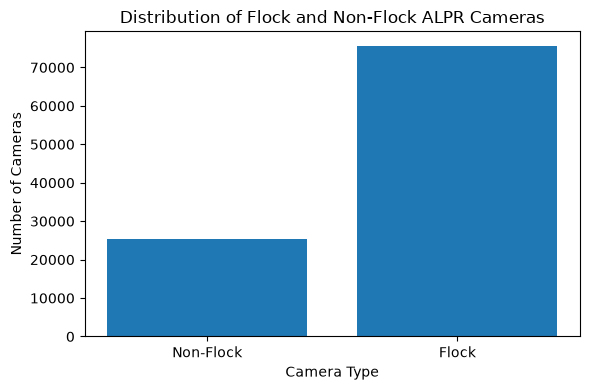

In [ ]:
import matplotlib.pyplot as plt

flock_counts = (
    alpr
    .group_by("flock")
    .len()
    .sort("flock")
)

plt.figure(figsize=(6, 4))
plt.bar(
    ["Non-Flock", "Flock"],
    flock_counts["len"]
)

plt.xlabel("Camera Type")
plt.ylabel("Number of Cameras")
plt.title("Distribution of Flock and Non-Flock ALPR Cameras")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The ALPR dataset contains substantially more Flock cameras than non-Flock cameras. Of the 101,085 records, 75,614 (74.8%) are identified as Flock cameras and 25,471 (25.2%) are identified as non-Flock cameras. This distribution is important because the research focuses specifically on Flock cameras. The dataset is not evenly divided between the two groups, so comparisons between Flock and non-Flock cameras should account for this difference

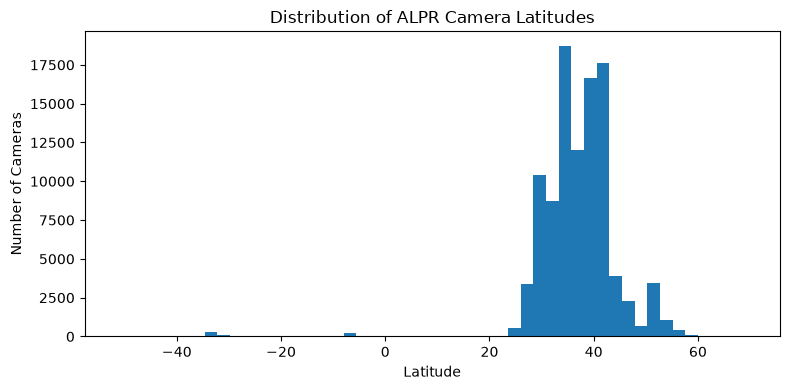

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(alpr["lat"], bins=50)

plt.xlabel("Latitude")
plt.ylabel("Number of Cameras")
plt.title("Distribution of ALPR Camera Latitudes")
plt.tight_layout()
plt.show()

The latitude distribution shows that the ALPR cameras are spread across a wide geographic range rather than being limited to Chicago. The distribution is centered around the mid-latitudes but includes cameras across multiple regions. This confirms that the dataset contains geographic data beyond the Chicago area, so the analysis will need to filter or focus on Chicago when examining the relationship between cameras and crime.

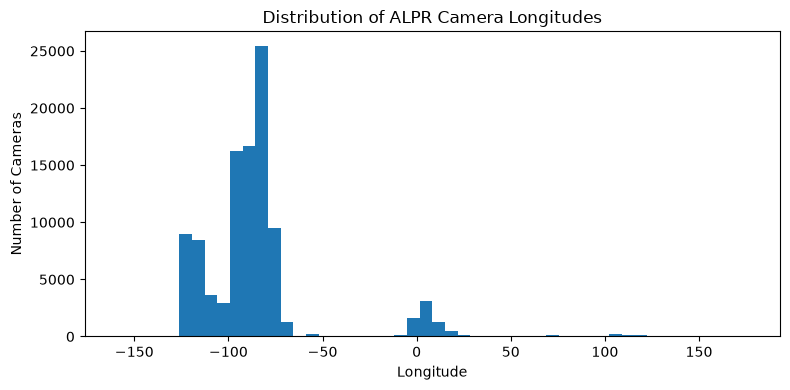

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(alpr["lon"], bins=50)

plt.xlabel("Longitude")
plt.ylabel("Number of Cameras")
plt.title("Distribution of ALPR Camera Longitudes")
plt.tight_layout()
plt.show()

The longitude distribution also shows that the ALPR dataset covers a broad geographic area. The wide spread of longitude values indicates that the dataset is not Chicago-specific. For the research questions, the Chicago subset will be more relevant when comparing camera locations with Chicago crime data.

In [ ]:
crime_2017.schema

Schema([('ID', Int64),
        ('Case Number', String),
        ('Date', String),
        ('Block', String),
        ('IUCR', String),
        ('Primary Type', String),
        ('Description', String),
        ('Location Description', String),
        ('Arrest', Boolean),
        ('Domestic', Boolean),
        ('Beat', Int64),
        ('District', Int64),
        ('Ward', Int64),
        ('Community Area', Int64),
        ('FBI Code', String),
        ('X Coordinate', Int64),
        ('Y Coordinate', Int64),
        ('Year', Int64),
        ('Updated On', String),
        ('Latitude', Float64),
        ('Longitude', Float64),
        ('Location', String)])

In [ ]:
crime_2017.head()

ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
i64,str,str,str,str,str,str,str,bool,bool,i64,i64,i64,i64,str,i64,i64,i64,str,f64,f64,str
11192233,"""JB100016""","""12/31/2017 11:58:00 PM""","""046XX N ST LOUIS AVE""","""0630""","""BURGLARY""","""ATTEMPT FORCIBLE ENTRY""","""APARTMENT""",false,false,1723,17,33,14,"""05""",1152214,1930694,2017,"""2018 May 04 03:51:04 PM""",41.965694,-87.715726,"""POINT (-87.715726125 41.965693…"
11196379,"""JB105867""","""12/31/2017 11:50:00 PM""","""024XX N LAKE SHORE DR NB""","""0460""","""BATTERY""","""SIMPLE""","""MOVIE HOUSE/THEATER""",false,false,1935,19,43,7,"""08B""",1175293,1916610,2017,"""2018 May 04 03:51:04 PM""",41.926559,-87.631294,"""POINT (-87.631294073 41.926558…"
11192540,"""JB100551""","""12/31/2017 11:48:00 PM""","""001XX E SUPERIOR ST""","""0890""","""THEFT""","""FROM BUILDING""","""HOTEL/MOTEL""",false,false,1833,18,42,8,"""06""",1177508,1905401,2017,"""2018 May 04 03:51:04 PM""",41.895751,-87.623496,"""POINT (-87.623495923 41.895750…"
11192254,"""JB100003""","""12/31/2017 11:45:00 PM""","""115XX S STATE ST""","""041A""","""BATTERY""","""AGGRAVATED: HANDGUN""","""RESIDENCE""",false,true,522,5,34,53,"""04B""",1178329,1828012,2017,"""2018 May 04 03:51:04 PM""",41.683369,-87.62283,"""POINT (-87.622829524 41.683369…"
11192239,"""JB100032""","""12/31/2017 11:45:00 PM""","""019XX S CANAL ST""","""1320""","""CRIMINAL DAMAGE""","""TO VEHICLE""","""STREET""",false,true,1235,12,25,31,"""14""",1173432,1891037,2017,"""2018 May 04 03:51:04 PM""",41.856427,-87.638893,"""POINT (-87.638892854 41.856426…"


In [ ]:
crime_2017.null_count()

ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,1375,0,0,0,1,1,15,0,4413,4413,0,0,4413,4413,4413


In [ ]:
crime_2017.describe()

statistic,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
str,f64,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,str,f64,f64,str
"""count""",269349.0,"""269349""","""269349""","""269349""","""269349""","""269349""","""269349""","""267974""",269349.0,269349.0,269349.0,269348.0,269348.0,269334.0,"""269349""",264936.0,264936.0,269349.0,"""269349""",264936.0,264936.0,"""264936"""
"""null_count""",0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""1375""",0.0,0.0,0.0,1.0,1.0,15.0,"""0""",4413.0,4413.0,0.0,"""0""",4413.0,4413.0,"""4413"""
"""mean""",1.0989e7,null,null,null,null,null,null,null,0.19569,0.187615,1146.02382,11.231069,23.270546,36.54823,null,1.1649e6,1.8866e6,2017.0,null,41.844493,-87.670217,null
"""std""",572775.094851,null,null,null,null,null,null,null,null,null,701.534324,7.007049,14.144244,21.403236,null,16116.819936,31269.795858,0.0,null,0.085992,0.058674,null
"""min""",23059.0,"""G183384""","""01/01/2017 01:00:00 AM""","""0000X E 100TH PL""","""0110""","""ARSON""","""$500 AND UNDER""","""ABANDONED BUILDING""",0.0,0.0,111.0,1.0,0.0,0.0,"""01A""",1.094231e6,1.813909e6,2017.0,"""2017 Apr 01 03:50:38 PM""",41.644606,-87.928909,"""POINT (-87.524529465 41.701938…"
"""25%""",1.0909907e7,null,null,null,null,null,null,null,null,null,611.0,6.0,10.0,23.0,null,1.153371e6,1.859405e6,2017.0,null,41.769597,-87.712289,null
"""50%""",1.1012756e7,null,null,null,null,null,null,null,null,null,1031.0,10.0,24.0,32.0,null,1.166685e6,1.894131e6,2017.0,null,41.865287,-87.664028,null
"""75%""",1.1109038e7,null,null,null,null,null,null,null,null,null,1722.0,17.0,35.0,53.0,null,1.176502e6,1.909087e6,2017.0,null,41.906365,-87.62776,null
"""max""",1.4328126e7,"""Z582023""","""12/31/2017 12:55:00 PM""","""137XX S LEYDEN AVE""","""5132""","""WEAPONS VIOLATION""","""VIOLENT OFFENDER: FAIL TO REGI…","""YARD""",1.0,1.0,6100.0,61.0,50.0,77.0,"""26""",1.205119e6,1.951535e6,2017.0,"""2026 Sep 16 03:44:40 PM""",42.022671,-87.524529,"""POINT (-87.928909442 41.969002…"


In [ ]:
crime_2017.shape

(269349, 22)

In [ ]:
crime_2017.unique().shape

(269349, 22)

In [ ]:
crime_2017.select(
    pl.col("ID").n_unique().alias("unique_ids"),
    pl.len().alias("total_rows")
)

unique_ids,total_rows
u32,u32
269349,269349


In [ ]:
crime_2017.select("Year").unique()

Year
i64
2017


In [ ]:
crime_2017.select(
    pl.col("Date").min().alias("earliest_date"),
    pl.col("Date").max().alias("latest_date")
)

earliest_date,latest_date
str,str
"""01/01/2017 01:00:00 AM""","""12/31/2017 12:55:00 PM"""


In [ ]:
crime_types_2017 = (
    crime_2017
    .group_by("Primary Type")
    .len()
    .sort("len", descending=True)
)

crime_types_2017

Primary Type,len
str,u32
"""THEFT""",64388
"""BATTERY""",49241
"""CRIMINAL DAMAGE""",29045
"""DECEPTIVE PRACTICE""",19832
"""ASSAULT""",19306
…,…
"""CONCEALED CARRY LICENSE VIOLAT…",69
"""OTHER NARCOTIC VIOLATION""",11
"""PUBLIC INDECENCY""",10


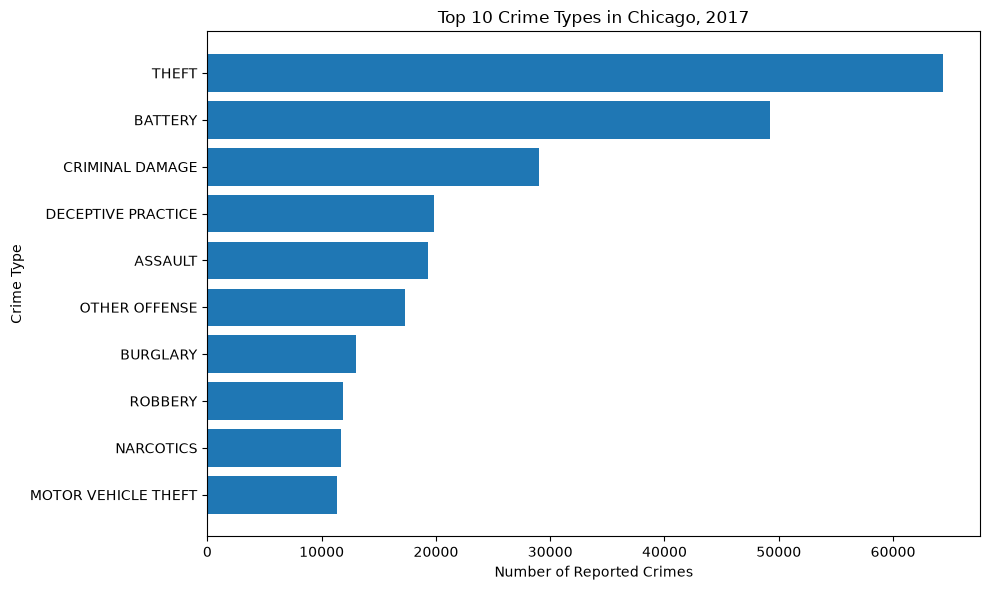

In [ ]:
top_crimes_2017 = crime_types_2017.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_crimes_2017["Primary Type"][::-1],
    top_crimes_2017["len"][::-1]
)

plt.xlabel("Number of Reported Crimes")
plt.ylabel("Crime Type")
plt.title("Top 10 Crime Types in Chicago, 2017")
plt.tight_layout()
plt.show()

The distribution of reported crime types in 2017 is highly uneven. Theft and battery account for substantially more records than the other crime categories, while several categories occur much less frequently. This suggests that total crime counts are strongly influenced by a small number of common crime types. For later analysis, it may be useful to examine whether the relationship between Flock camera locations and crime differs across major crime categories rather than relying only on total crime.

In [ ]:
crime_2017 = crime_2017.with_columns(
    pl.col("Date").str.to_datetime("%m/%d/%Y %I:%M:%S %p").alias("Date")
)

crime_2017.select("Date").head()

Date
datetime[μs]
2017-12-31 23:58:00
2017-12-31 23:50:00
2017-12-31 23:48:00
2017-12-31 23:45:00
2017-12-31 23:45:00


In [ ]:
monthly_crime_2017 = (
    crime_2017
    .with_columns(
        pl.col("Date").dt.month().alias("Month")
    )
    .group_by("Month")
    .len()
    .sort("Month")
)

monthly_crime_2017


Month,len
i8,u32
1,22247
2,19331
3,20603
4,21723
5,23412
…,…
8,24764
9,22874
10,22956


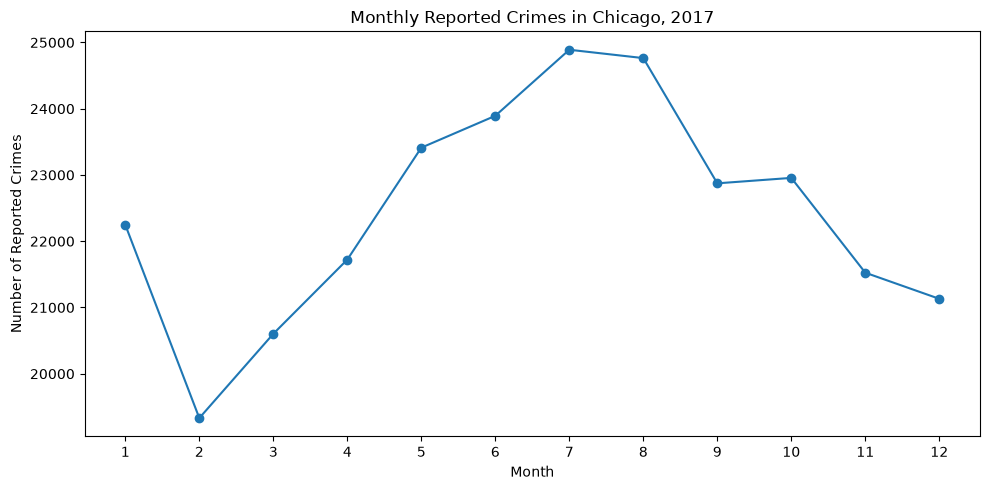

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_crime_2017["Month"],
    monthly_crime_2017["len"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Number of Reported Crimes")
plt.title("Monthly Reported Crimes in Chicago, 2017")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

The number of reported crimes varies throughout 2017, with lower totals during some months and higher totals during the summer. July has the highest number of reported crimes, while February has one of the lowest totals. Overall, the monthly totals fluctuate but remain within a relatively similar range throughout the year, suggesting some seasonal variation without a dramatic change in total reported crime.

In [ ]:
crime_2026.schema

Schema([('ID', Int64),
        ('Case Number', String),
        ('Date', String),
        ('Block', String),
        ('IUCR', String),
        ('Primary Type', String),
        ('Description', String),
        ('Location Description', String),
        ('Arrest', Boolean),
        ('Domestic', Boolean),
        ('Beat', Int64),
        ('District', Int64),
        ('Ward', Int64),
        ('Community Area', Int64),
        ('FBI Code', String),
        ('X Coordinate', Int64),
        ('Y Coordinate', Int64),
        ('Year', Int64),
        ('Updated On', String),
        ('Latitude', Float64),
        ('Longitude', Float64),
        ('Location', String)])

In [ ]:
crime_2026.shape

(167474, 22)

In [ ]:
crime_2026.head()

ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
i64,str,str,str,str,str,str,str,bool,bool,i64,i64,i64,i64,str,i64,i64,i64,str,f64,f64,str
14334571,"""JK421628""","""09/20/2026 12:00:00 AM""","""028XX S ARCHER AVE""","""1121""","""DECEPTIVE PRACTICE""","""COUNTERFEITING DOCUMENT""","""COMMERCIAL / BUSINESS OFFICE""",false,false,913,9,11,60,"""10""",1168555,1885790,2026,"""09/27/2026 03:42:09 PM""",41.842135,-87.656946,"""POINT (-87.656945593 41.842135…"
14333356,"""JK420268""","""09/20/2026 12:00:00 AM""","""088XX S LOWE AVE""","""1320""","""CRIMINAL DAMAGE""","""TO VEHICLE""","""STREET""",false,false,2223,22,21,71,"""14""",1173516,1846365,2026,"""09/27/2026 03:42:09 PM""",41.73384,-87.639907,"""POINT (-87.639907164 41.733840…"
14333481,"""JK420566""","""09/20/2026 12:00:00 AM""","""006XX N DEARBORN ST""","""0810""","""THEFT""","""OVER $500""","""STREET""",false,false,1832,18,42,8,"""06""",1175822,1904684,2026,"""09/27/2026 03:42:09 PM""",41.893822,-87.62971,"""POINT (-87.629709751 41.893821…"
14335903,"""JK423456""","""09/20/2026 12:00:00 AM""","""022XX S KEDZIE AVE""","""0760""","""BURGLARY""","""BURGLARY FROM MOTOR VEHICLE""","""STREET""",false,false,1024,10,24,30,"""06""",1155373,1888980,2026,"""09/27/2026 03:42:09 PM""",41.851164,-87.705234,"""POINT (-87.705234173 41.851163…"
14335596,"""JK423038""","""09/20/2026 12:00:00 AM""","""017XX N WELLS ST""","""1152""","""DECEPTIVE PRACTICE""","""ILLEGAL USE CASH CARD""","""STREET""",false,false,1814,18,43,7,"""11""",1174387,1911687,2026,"""09/27/2026 03:42:09 PM""",41.91307,-87.634771,"""POINT (-87.634770532 41.913070…"


In [ ]:
crime_2026.null_count()

ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,758,0,0,0,0,0,1,0,304,304,0,0,304,304,304


In [ ]:
crime_2026.describe()

statistic,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
str,f64,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,str,f64,f64,str
"""count""",167474.0,"""167474""","""167474""","""167474""","""167474""","""167474""","""167474""","""166716""",167474.0,167474.0,167474.0,167474.0,167474.0,167473.0,"""167474""",167170.0,167170.0,167474.0,"""167474""",167170.0,167170.0,"""167170"""
"""null_count""",0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""758""",0.0,0.0,0.0,0.0,0.0,1.0,"""0""",304.0,304.0,0.0,"""0""",304.0,304.0,"""304"""
"""mean""",1.4178e7,null,null,null,null,null,null,null,0.154723,0.192943,1149.787692,11.266495,22.882023,36.178614,null,1.1657e6,1.8871e6,2026.0,null,41.845748,-87.667339,null
"""std""",618808.403252,null,null,null,null,null,null,null,null,null,733.252494,7.325052,13.910744,21.358622,null,16200.262567,31198.193219,0.0,null,0.085795,0.058985,null
"""min""",29000.0,"""HK572868""","""01/01/2026 01:00:00 AM""","""0000X E 100TH PL""","""0110""","""ARSON""","""$500 AND UNDER""","""ABANDONED BUILDING""",0.0,0.0,111.0,1.0,0.0,0.0,"""01A""",1.094587e6,1.813897e6,2026.0,"""01/13/2026 03:57:41 PM""",41.64459,-87.927365,"""POINT (-87.524529378 41.702237…"
"""25%""",1.4139749e7,null,null,null,null,null,null,null,null,null,531.0,5.0,10.0,22.0,null,1.154475e6,1.860263e6,2026.0,null,41.772017,-87.708254,null
"""50%""",1.4204381e7,null,null,null,null,null,null,null,null,null,1032.0,10.0,23.0,32.0,null,1.167644e6,1.893598e6,2026.0,null,41.863751,-87.659958,null
"""75%""",1.4269916e7,null,null,null,null,null,null,null,null,null,1731.0,17.0,34.0,53.0,null,1.176961e6,1.909734e6,2026.0,null,41.908176,-87.626156,null
"""max""",1.4340599e7,"""JL192999""","""09/20/2026 12:00:00 AM""","""137XX S LEYDEN AVE""","""5132""","""WEAPONS VIOLATION""","""WIC FRAUD""","""YARD""",1.0,1.0,6100.0,61.0,50.0,77.0,"""26""",1.205116e6,1.951495e6,2026.0,"""09/27/2026 03:42:09 PM""",42.022548,-87.524529,"""POINT (-87.927364891 42.006074…"


### What Stands Out

* **167,474 crime records** are included in the dataset.
* The data covers **January 1, 2026 through September 20, 2026** based on the Date field.
* The Year column is consistently **2026**.
* About **15.5%** of reported crimes resulted in an arrest.
* About **19.3%** of reported crimes are marked as domestic.
* Latitude ranges from approximately **41.64 to 42.02**.
* Longitude ranges from approximately **-87.93 to -87.52**, which is consistent with the Chicago area.
* There are **758 missing Location Description** values.
* There is **1 missing Community Area** value.
* **304 records** are missing geographic coordinates and location information.
* The Date and Updated On columns are stored as strings, so Date should be converted to a datetime format before performing time-based analysis.
* The dataset does **not cover the complete 2026 year**, so it should be treated as **2026 year-to-date (YTD)** when making comparisons. It should not be directly compared with the full-year 2017 crime total without accounting for the different time periods.


In [ ]:
crime_2026.unique().shape

(167474, 22)

In [ ]:
crime_2026.select(
    pl.col("ID").n_unique().alias("unique_ids"),
    pl.len().alias("total_rows")
)

unique_ids,total_rows
u32,u32
167474,167474


No Duplicate rows

In [ ]:
crime_2026.select("Year").unique().sort("Year")

Year
i64
2026


Year check is good

In [ ]:
crime_2026.filter(
    (pl.col("Latitude") < -90) |
    (pl.col("Latitude") > 90) |
    (pl.col("Longitude") < -180) |
    (pl.col("Longitude") > 180)
).shape

(0, 22)

No invalid coords

In [ ]:
crime_types_2026 = (
    crime_2026
    .group_by("Primary Type")
    .len()
    .sort("len", descending=True)
)

crime_types_2026

Primary Type,len
str,u32
"""THEFT""",36122
"""BATTERY""",30875
"""CRIMINAL DAMAGE""",18368
"""ASSAULT""",15194
"""MOTOR VEHICLE THEFT""",13211
…,…
"""HUMAN TRAFFICKING""",25
"""PUBLIC INDECENCY""",18
"""GAMBLING""",13


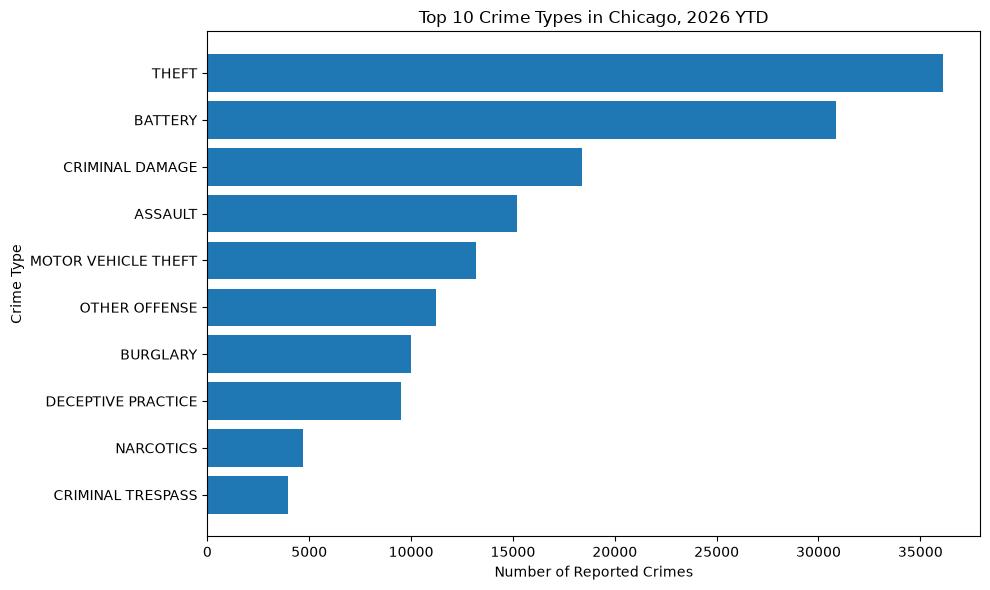

In [ ]:
top_crimes_2026 = crime_types_2026.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_crimes_2026["Primary Type"][::-1],
    top_crimes_2026["len"][::-1]
)
plt.xlabel("Number of Reported Crimes")
plt.ylabel("Crime Type")
plt.title("Top 10 Crime Types in Chicago, 2026 YTD")
plt.tight_layout()
plt.show()

The distribution of reported crime types in Chicago in 2026 YTD is highly uneven. Theft and battery are the most common reported crime types, followed by criminal damage, assault, and motor vehicle theft. Several other crime categories occur much less frequently. This shows that a small number of crime types account for a large portion of reported crimes. This is important for later analysis because the relationship between Flock cameras and crime may differ depending on the type of crime being examined.

In [ ]:
crime_2026 = crime_2026.with_columns(
    pl.col("Date").str.to_datetime(
        "%m/%d/%Y %I:%M:%S %p"
    ).alias("Date")
)

crime_2026.select("Date").head()

Date
datetime[μs]
2026-09-20 00:00:00
2026-09-20 00:00:00
2026-09-20 00:00:00
2026-09-20 00:00:00
2026-09-20 00:00:00


In [ ]:
monthly_crime_2026 = (
    crime_2026
    .with_columns(
        pl.col("Date").dt.month().alias("Month")
    )
    .group_by("Month")
    .len()
    .sort("Month")
)

monthly_crime_2026

Month,len
i8,u32
1,17030
2,16542
3,19178
4,19140
5,21143
6,20030
7,21233
8,20715
9,12463


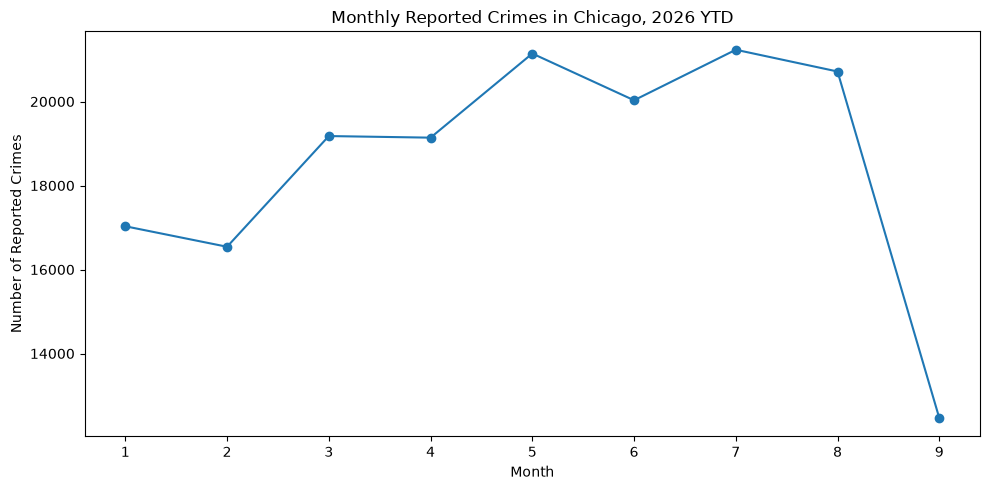

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_crime_2026["Month"],
    monthly_crime_2026["len"],
    marker="o"
)

plt.xlabel("Month")
plt.ylabel("Number of Reported Crimes")
plt.title("Monthly Reported Crimes in Chicago, 2026 YTD")
plt.xticks(range(1, 10))
plt.tight_layout()
plt.show()

Reported crime counts vary across the months included in the 2026 YTD dataset. Crime counts generally increase from January through July, with July having the highest number of reported crimes among the complete months. August remains relatively high, while September has a noticeably lower count. But, September only includes incidents through September 20, so its lower total should not be interpreted as a true decrease in crime. Overall, the monthly distribution shows some variation throughout the year, but the partial September data limits comparisons for that month.

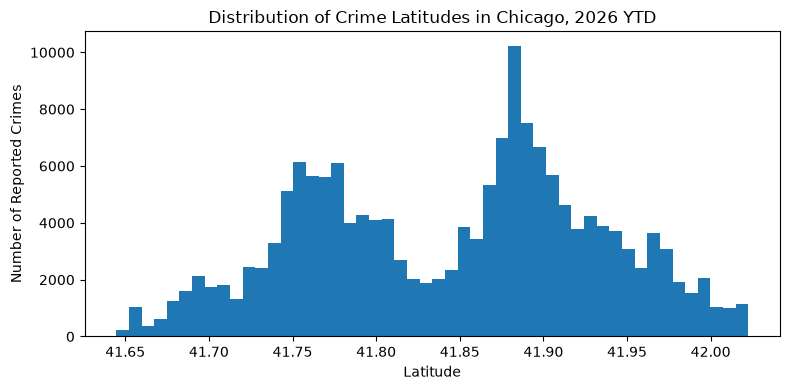

In [ ]:
plt.figure(figsize=(8, 4))

plt.hist(crime_2026["Latitude"].drop_nulls(), bins=50)

plt.xlabel("Latitude")
plt.ylabel("Number of Reported Crimes")
plt.title("Distribution of Crime Latitudes in Chicago, 2026 YTD")
plt.tight_layout()
plt.show()

The latitude values are concentrated within a relatively narrow range, which is expected because the dataset represents reported crimes within Chicago. The distribution shows where reported crimes are geographically concentrated from north to south. There are no invalid latitude values, although 304 records have missing geographic coordinates and are excluded from this plot.

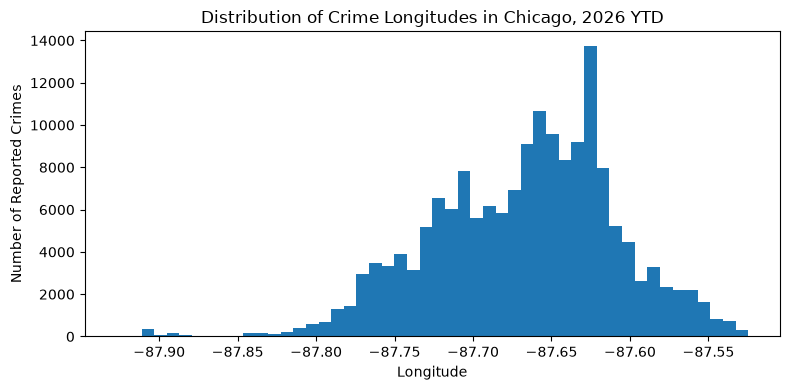

In [ ]:
plt.figure(figsize=(8, 4))

plt.hist(crime_2026["Longitude"].drop_nulls(), bins=50)

plt.xlabel("Longitude")
plt.ylabel("Number of Reported Crimes")
plt.title("Distribution of Crime Longitudes in Chicago, 2026 YTD")
plt.tight_layout()
plt.show()

The longitude values are concentrated within a relatively narrow range, which is expected because the dataset represents reported crimes within Chicago. The distribution shows how reported crimes are geographically distributed from west to east across the city. There are no invalid longitude values, although 304 records have missing geographic coordinates and are excluded from this plot.

In [ ]:
alpr_chicago = alpr.filter(
    (pl.col("lat") >= 41.64) &
    (pl.col("lat") <= 42.03) &
    (pl.col("lon") >= -87.94) &
    (pl.col("lon") <= -87.52)
)

alpr_chicago.shape

(1101, 4)

In [ ]:
chicago_camera_types = (
    alpr_chicago
    .group_by("flock")
    .len()
    .sort("flock")
)

chicago_camera_types

flock,len
i64,u32
0,619
1,482


In [ ]:
crime_2026_geo = crime_2026.filter(
    pl.col("Latitude").is_not_null() &
    pl.col("Longitude").is_not_null()
)

crime_2026_geo.shape

(167170, 22)

In [ ]:
flock_chicago = alpr_chicago.filter(
    pl.col("flock") == 1
)

flock_chicago.shape

(482, 4)

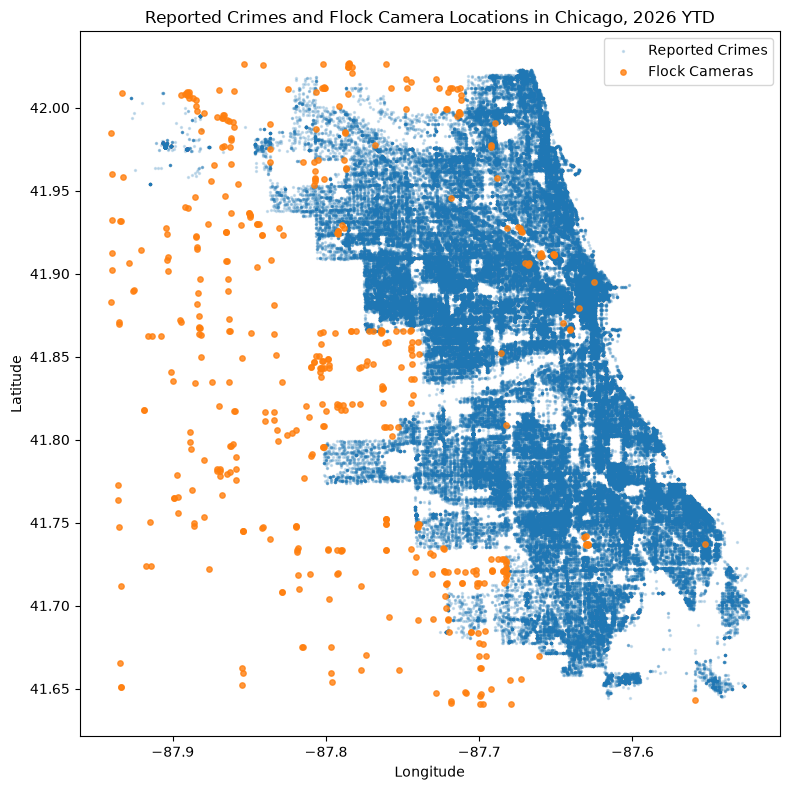

In [ ]:
plt.figure(figsize=(8, 8))

plt.scatter(
    crime_2026_geo["Longitude"],
    crime_2026_geo["Latitude"],
    s=2,
    alpha=0.2,
    label="Reported Crimes"
)

plt.scatter(
    flock_chicago["lon"],
    flock_chicago["lat"],
    s=15,
    alpha=0.8,
    label="Flock Cameras"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Reported Crimes and Flock Camera Locations in Chicago, 2026 YTD")
plt.legend()
plt.tight_layout()
plt.show()

The spatial distribution shows some overlap between reported crime and Flock camera locations. Several Flock cameras appear in areas with higher concentrations of reported crime, but many cameras are also located outside the densest crime clusters. This suggests that camera placement is not determined solely by reported crime density. However, this plot is descriptive and does not measure the strength of the relationship statistically.

A useful next step is to compare the number of Flock cameras with the number of reported crimes across smaller geographic areas within Chicago. This would allow us to determine whether areas with more Flock cameras also tend to have more reported crime.

In [ ]:
monthly_crime_arrest_2026 = (
    crime_2026
    .with_columns(
        pl.col("Date").dt.month().alias("Month")
    )
    .group_by("Month")
    .agg([
        pl.len().alias("Crime Count"),
        pl.col("Arrest").mean().alias("Arrest Rate")
    ])
    .sort("Month")
)

monthly_crime_arrest_2026

Month,Crime Count,Arrest Rate
i8,u32,f64
1,17030,0.167645
2,16542,0.166002
3,19178,0.155647
4,19140,0.151881
5,21143,0.14156
6,20030,0.155317
7,21233,0.157161
8,20715,0.151822
9,12463,0.147075


In [ ]:
crime_type_arrest_2026 = (
    crime_2026
    .group_by("Primary Type")
    .agg([
        pl.len().alias("Crime Count"),
        pl.col("Arrest").mean().alias("Arrest Rate")
    ])
    .sort("Crime Count", descending=True)
)

crime_type_arrest_2026

Primary Type,Crime Count,Arrest Rate
str,u32,f64
"""THEFT""",36122,0.08989
"""BATTERY""",30875,0.192939
"""CRIMINAL DAMAGE""",18368,0.045949
"""ASSAULT""",15194,0.136567
"""MOTOR VEHICLE THEFT""",13211,0.037166
…,…,…
"""HUMAN TRAFFICKING""",25,0.0
"""PUBLIC INDECENCY""",18,0.888889
"""GAMBLING""",13,1.0


In [ ]:
top_crime_arrest_2026 = (
    crime_type_arrest_2026
    .head(10)
    .sort("Arrest Rate", descending=True)
)

top_crime_arrest_2026

Primary Type,Crime Count,Arrest Rate
str,u32,f64
"""NARCOTICS""",4714,0.9493
"""CRIMINAL TRESPASS""",3981,0.333585
"""BATTERY""",30875,0.192939
"""OTHER OFFENSE""",11224,0.166429
"""ASSAULT""",15194,0.136567
"""THEFT""",36122,0.08989
"""CRIMINAL DAMAGE""",18368,0.045949
"""MOTOR VEHICLE THEFT""",13211,0.037166
"""BURGLARY""",10004,0.028289


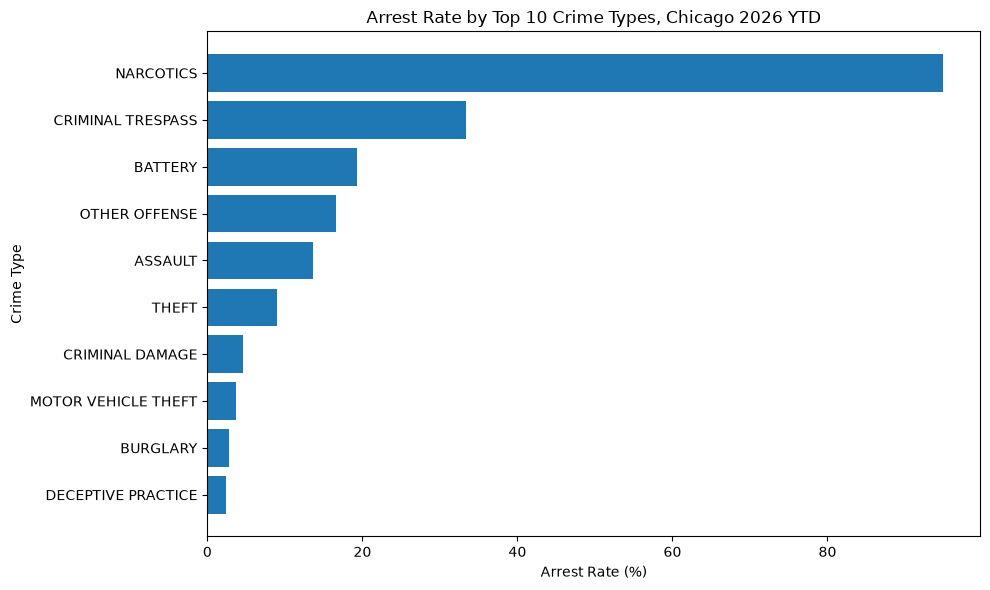

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_crime_arrest_2026["Primary Type"][::-1],
    top_crime_arrest_2026["Arrest Rate"][::-1] * 100
)

plt.xlabel("Arrest Rate (%)")
plt.ylabel("Crime Type")
plt.title("Arrest Rate by Top 10 Crime Types, Chicago 2026 YTD")
plt.tight_layout()
plt.show()

The arrest rate varies substantially across the most common crime types in Chicago in 2026 YTD. Narcotics has a much higher arrest rate than the other crime types, at about 94.9%. Criminal trespass also has a relatively high arrest rate at about 33.4%, while common crimes such as theft, criminal damage, motor vehicle theft, burglary, and deceptive practice have much lower arrest rates. This shows that the likelihood of an arrest varies considerably depending on the type of crime reported. However, this relationship does not tell us whether Flock cameras contributed to arrests or crime outcomes.



A useful next step is to examine whether the relationship between Flock camera locations and reported crime differs across crime types. For example, we could compare the locations of Flock cameras with areas where specific common crimes, such as theft, battery, or motor vehicle theft, are frequently reported. This could help determine whether camera placement overlaps more strongly with certain types of reported crime.

In [ ]:
grid_size = 0.02

flock_grid = (
    flock_chicago
    .with_columns([
        (pl.col("lat") / grid_size).floor().alias("lat_grid"),
        (pl.col("lon") / grid_size).floor().alias("lon_grid")
    ])
    .group_by(["lat_grid", "lon_grid"])
    .len()
    .rename({"len": "Flock Cameras"})
)

crime_grid = (
    crime_2026_geo
    .with_columns([
        (pl.col("Latitude") / grid_size).floor().alias("lat_grid"),
        (pl.col("Longitude") / grid_size).floor().alias("lon_grid")
    ])
    .group_by(["lat_grid", "lon_grid"])
    .len()
    .rename({"len": "Reported Crimes"})
)

In [ ]:
camera_crime_grid = (
    crime_grid
    .join(
        flock_grid,
        on=["lat_grid", "lon_grid"],
        how="left"
    )
    .with_columns(
        pl.col("Flock Cameras").fill_null(0)
    )
)

camera_crime_grid

lat_grid,lon_grid,Reported Crimes,Flock Cameras
f64,f64,u32,u32
2097.0,-4392.0,143,0
2084.0,-4379.0,28,0
2094.0,-4386.0,2222,0
2084.0,-4383.0,880,0
2087.0,-4384.0,1331,0
…,…,…,…
2089.0,-4384.0,1203,0
2085.0,-4379.0,553,0
2091.0,-4386.0,263,0


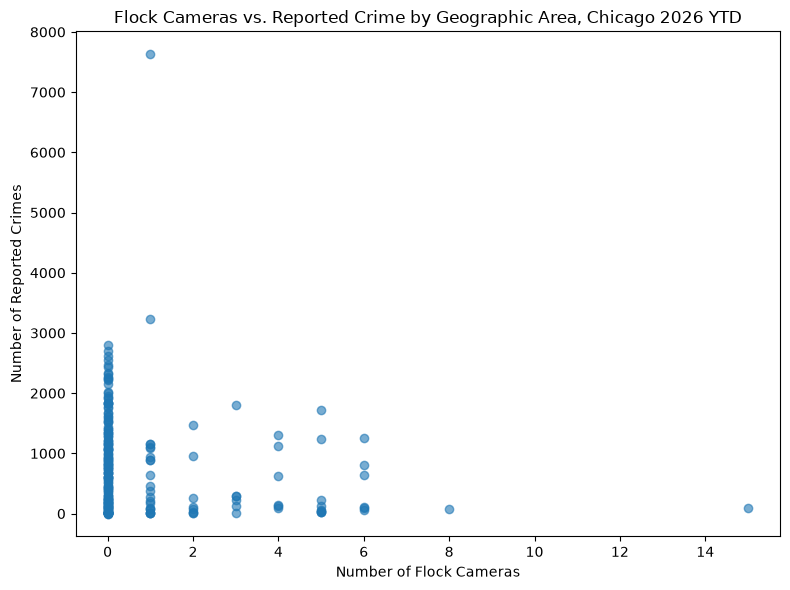

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    camera_crime_grid["Flock Cameras"],
    camera_crime_grid["Reported Crimes"],
    alpha=0.6
)

plt.xlabel("Number of Flock Cameras")
plt.ylabel("Number of Reported Crimes")
plt.title("Flock Cameras vs. Reported Crime by Geographic Area, Chicago 2026 YTD")
plt.tight_layout()
plt.show()

The scatter plot suggests a weak and inconsistent relationship between the number of Flock cameras and reported crime. Areas with few or no Flock cameras show a wide range of reported crime levels, including some of the highest crime counts. As the number of cameras increases, there is no clear upward or downward trend in reported crime. This suggests that the number of Flock cameras in a geographic area is not strongly associated with the number of reported crimes. This is important because it suggests that simply having more Flock cameras in an area does not necessarily correspond to having more reported crime.

A useful next step would be to examine whether this relationship changes for specific types of crime, such as motor vehicle theft, theft, or battery. This could show whether Flock cameras are more commonly located in areas with certain types of reported crime rather than overall crime.

## Revised Research Questions


**What relationship exists between the geographic distribution of Flock Safety ALPR cameras and reported crime in Chicago in 2026?**

also considering the following questions:

1. Are Flock cameras located in areas with higher concentrations of reported crime?
2. Does the relationship between Flock cameras and reported crime vary across different types of crime?
3. How does reported crime vary across different geographic areas of Chicago?

## Overall Findings

The exploratory analysis shows that Flock cameras and reported crime have some geographic overlap in Chicago, but the number of Flock cameras in an area does not show a strong or consistent relationship with the number of reported crimes. Areas with few or no Flock cameras can still have high numbers of reported crimes.

Crime types also have substantially different arrest rates. Narcotics has a much higher arrest rate than the other common crime categories, while crimes such as theft, burglary, and motor vehicle theft have relatively low arrest rates.

The analysis also identified missing geographic information in the crime datasets. These records were retained in the original datasets but excluded from geographic plots when latitude or longitude was missing. The 2026 crime dataset only covers January through September 20, 2026, so it should be treated as year-to-date data rather than a complete year.

These findings suggest that Flock camera placement should be examined more closely by crime type and geographic area rather than assuming that more cameras correspond to more reported crime.


In [ ]:
#########################
# LEXI's EDA STOPS HERE #
#########################

In [ ]:
###############
# AHMAD's EDA #
###############

In [ ]:
import json
import polars as pl

from cs418_flock_research.alpr_cameras import load_alpr_cameras

from cs418_flock_research.atlas import load_atlas
atlas_raw = pl.read_csv("../data/raw/atlas_of_surveillance_2026-09-28.csv")

# chicago-city.geojson
city  = json.load(open("../data/raw/chicago-city.geojson"))

# chicago-wards.geojson
wards = json.load(open("../data/raw/chicago-wards.geojson"))   # needs: import json

# chicago-ward-income.csv
ward_income = pl.read_csv("../data/raw/chicago-ward-income.csv")

from cs418_flock_research.census import load_zcta

## Step 1: Dataset Profiles
Shape, types, missing values, and summary stats for each dataset, with a note on what stands out.

In [ ]:
cams = load_alpr_cameras("Illinois_alpr.geojson")

print("ALPR cameras rows, columns:", cams.shape) # Long Format Good

ALPR cameras rows, columns: (8047, 11)


In [ ]:
print("number_of_unique_rows, number_of_columns)", cams.unique().shape) # Every row is unique Good, no duplicates

number_of_unique_rows, number_of_columns) (8047, 11)


In [ ]:
cams.schema

Schema([('osm_id', Int64),
        ('lon', Float64),
        ('lat', Float64),
        ('operator', String),
        ('manufacturer', String),
        ('direction', String),
        ('surveillance_type', String),
        ('man_made', String),
        ('timestamp', Datetime(time_unit='us', time_zone='UTC')),
        ('version', Int64),
        ('all_tags', String)])

In [ ]:
cams.glimpse()

Rows: 8047
Columns: 11
$ osm_id                          <i64> 235538250, 237644546, 261326106, 261350820, 643776207, 2399926820, 2986637275, 4133803370, 6577258293, 7025421509
$ lon                             <f64> -88.126047, -88.153174, -87.6419063, -87.9559097, -89.0653851, -87.9062513, -87.6253803, -89.6035781, -87.9430478, -87.6267914
$ lat                             <f64> 42.168572, 41.974905, 41.9004337, 41.6691111, 42.3387912, 42.1899534, 41.7508605, 39.8309917, 42.2043405, 41.8909987
$ operator                        <str> null, null, null, null, null, null, null, 'Flock Safety', null, null
$ manufacturer                    <str> 'Flock Safety', 'Flock Safety', null, null, 'Flock Safety', 'Flock Safety', 'Motorola Solutions', 'Flock Safety', 'Flock Safety', null
$ direction                       <str> '180', '120', '175', '180;90', '205', '182', '180;160;170;150;190', '90', '145', '165'
$ surveillance_type               <str> 'ALPR', 'ALPR', 'ALPR', 'ALPR', 'ALPR', 'ALPR', 

In [ ]:
cams.head()

osm_id,lon,lat,operator,manufacturer,direction,surveillance_type,man_made,timestamp,version,all_tags
i64,f64,f64,str,str,str,str,str,"datetime[μs, UTC]",i64,str
235538250,-88.126047,42.168572,null,"""Flock Safety""","""180""","""ALPR""","""surveillance""",2025-08-23 12:05:17 UTC,3,"""{""camera:type"": ""fixed"", ""dire…"
237644546,-88.153174,41.974905,null,"""Flock Safety""","""120""","""ALPR""","""surveillance""",2026-02-10 17:06:28 UTC,4,"""{""camera:type"": ""fixed"", ""dire…"
261326106,-87.641906,41.900434,null,null,"""175""","""ALPR""","""surveillance""",2025-09-03 16:59:09 UTC,6,"""{""camera:type"": ""fixed"", ""dire…"
261350820,-87.95591,41.669111,null,null,"""180;90""","""ALPR""","""surveillance""",2026-05-29 06:03:13 UTC,8,"""{""direction"": ""180;90"", ""man_m…"
643776207,-89.065385,42.338791,null,"""Flock Safety""","""205""","""ALPR""","""surveillance""",2025-10-27 13:51:01 UTC,3,"""{""camera:type"": ""fixed"", ""dire…"


In [ ]:
cams.null_count()

osm_id,lon,lat,operator,manufacturer,direction,surveillance_type,man_made,timestamp,version,all_tags
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,7064,643,525,0,4,0,0,0


In [ ]:
cams.select(
    pl.col("manufacturer").null_count(),
    pl.col("operator").null_count(),
    pl.col("lat").null_count(),
    pl.col("lon").null_count(),
    pl.col("timestamp").null_count(),
)

manufacturer,operator,lat,lon,timestamp
u32,u32,u32,u32,u32
643,7064,0,0,0


In [ ]:
cams.group_by("manufacturer").len().sort("len", descending=True)

manufacturer,len
str,u32
"""Flock Safety""",5772
"""Motorola Solutions""",761
null,643
"""Axis communications""",500
"""Genetec""",228
…,…
"""RedSpeed USA""",2
"""Unknown""",2
"""Sensys Gatso Group""",2


In [ ]:
cams.group_by("operator").len().sort("len", descending=True).head(10)

operator,len
str,u32
null,7064
"""Flock Safety""",416
"""Chicago Police Department""",225
"""Illinois State Police""",72
"""Champaign Police Department""",63
"""Wood Dale Police Department""",28
"""Lowe's""",17
"""Highland Park Police Departmen…",15
"""Plainfield Police""",12


In [ ]:
# cameras added per year (only accurate where version == 1, since timestamp is the last edit)
(
    cams.filter(pl.col("version") == 1)
    .group_by(pl.col("timestamp").dt.year().alias("year"))
    .len()
    .sort("year")
)

year,len
i32,u32
2023,8
2024,196
2025,2435
2026,3818


In [ ]:
cams.filter(
    pl.col("lat").is_between(41.6, 42.1),
    pl.col("lon").is_between(-87.95, -87.5),
)

osm_id,lon,lat,operator,manufacturer,direction,surveillance_type,man_made,timestamp,version,all_tags
i64,f64,f64,str,str,str,str,str,"datetime[μs, UTC]",i64,str
261326106,-87.641906,41.900434,null,null,"""175""","""ALPR""","""surveillance""",2025-09-03 16:59:09 UTC,6,"""{""camera:type"": ""fixed"", ""dire…"
2986637275,-87.62538,41.750861,null,"""Motorola Solutions""","""180;160;170;150;190""","""ALPR""","""surveillance""",2025-12-22 17:16:54 UTC,5,"""{""camera:type"": ""fixed"", ""dire…"
7025421509,-87.626791,41.890999,null,null,"""165""","""ALPR""","""surveillance""",2025-09-03 14:50:19 UTC,3,"""{""camera:type"": ""fixed"", ""dire…"
9213232773,-87.787724,41.985833,"""Chicago Police Department""",null,"""180""","""ALPR""","""surveillance""",2024-08-27 03:16:23 UTC,3,"""{""camera:mount"": ""traffic_sign…"
9213245005,-87.76978,41.923837,"""Chicago Police Department""",null,"""90""","""ALPR""","""surveillance""",2024-08-27 09:25:50 UTC,4,"""{""camera:mount"": ""lighting_pol…"
…,…,…,…,…,…,…,…,…,…,…
14216052134,-87.605484,41.785766,"""University of Chicago Police D…","""Genetec""","""300""","""ALPR""","""surveillance""",2026-09-25 19:19:43 UTC,1,"""{""camera:mount"": ""emergency_ph…"
14216149402,-87.838591,41.742796,null,"""Flock Safety""","""144""","""ALPR""","""surveillance""",2026-09-25 20:03:56 UTC,1,"""{""camera:type"": ""fixed"", ""dire…"
14217077101,-87.771212,41.847107,null,"""Flock Safety""","""187""","""ALPR""","""surveillance""",2026-09-26 00:19:20 UTC,1,"""{""camera:type"": ""fixed"", ""dire…"


In [ ]:
cams.filter(pl.col("manufacturer") == "Flock Safety").select(
    pl.col("lat").mean(), pl.col("lon").mean()
)

lat,lon
f64,f64
41.238864,-88.490809


In [ ]:
cams.filter(pl.col("lat").is_between(41.64, 42.02) & pl.col("lon").is_between(-87.94, -87.52)).group_by((pl.col("manufacturer") == "Flock Safety").alias("flock")).len()

flock,len
bool,u32
null,403
false,941
true,698


Illinois_alpr.geojson

What stands out (OSM ALPR cameras): 
- cams.shape and cams.unique().shape both give (8047, 11), 
- so there are 8,047 cameras assuming no duplicate rows, 
- and null_count() shows 0 missing lon, lat, and timestamp, which is good because almost everything I want to do depends on where and when the cameras were mapped.
- However, null_count() shows operator is missing for 7,064 rows (7,064 / 8,047 = 88%), and the only operator value in the first 10 rows of glimpse() is 'Flock Safety', which is the company that makes the camera and not the agency that runs it.
- Additionally, my group by shows 5,772 cameras are 'Flock Safety' (5,772 / 8,047 = 72%), and the 643 cameras with no manufacturer end up in their own null group, 
- So honestly 72% is really the minimum share of Flock cameras. 
- The loader keeps direction as text on purpose, and glimpse() shows why, since some cameras have one angle like '180' while others have lists like '180;160;170;150;190', 
- so this column can't be used as a number without cleaning it first. 
- The loader stores the original OSM tags in all_tags as JSON text and converts timestamp to a datetime. 
- In OSM, timestamp records when the record was last edited, not necessarily when the camera was installed. 
- e.g. The first ten rows have version numbers from 2 to 8, so those records have each been edited at least once since they were added to OSM.
- The loader doesn't actually fix any values, it just reshapes the GeoJSON into a table, one row per camera.
- It pulls lon and lat out of geometry, and since GeoJSON stores coordinates as [lon, lat] (longitude first), the order matters,
- and null_count() showing 0 for both means every camera got a location.
- Additionally, it sets the column types by hand (CAMERA_SCHEMA) instead of letting polars guess, since most fields are null for a lot of cameras and polars could guess the wrong type.
- It uses props.get(), so if a camera doesn't have a tag it just becomes null,
- so honestly the 7,064 operator nulls mean nobody tagged it in OSM, not that the loader lost it.
- So, only 11 fields get their own column, and every other OSM tag (like surveillance:zone and camera:mount) only lives inside all_tags.

In [ ]:
atlas_loaded = load_atlas()

print("Atlas rows, columns:", atlas_loaded.shape) # (15135, 13)

Atlas rows, columns: (15135, 13)


In [ ]:
print("number_of_unique_rows, number_of_columns)", atlas_loaded.unique().shape) # (15133, 13), so 2 rows are exact duplicates

number_of_unique_rows, number_of_columns) (15133, 13)


In [ ]:
atlas_loaded.filter(pl.col("aos_id").is_duplicated()).select("aos_id", "agency", "technology") # which rows are duplicated

aos_id,agency,technology
str,str,str
"""AOS010074""","""Burleson Police Department""","""Body-worn Cameras"""
"""AOS010074""","""Burleson Police Department""","""Body-worn Cameras"""
"""AOS013931""","""Orlando Police Department""","""Automated License Plate Reader…"
"""AOS013931""","""Orlando Police Department""","""Automated License Plate Reader…"


In [ ]:
atlas_loaded.schema

Schema([('aos_id', String),
        ('ori_tech_id', String),
        ('agency', String),
        ('agency_type', String),
        ('jurisdiction_type', String),
        ('city', String),
        ('county', String),
        ('state', String),
        ('technology', String),
        ('vendor', String),
        ('summary', String),
        ('source_url', String),
        ('source_date', Date)])

In [ ]:
atlas_loaded.glimpse()

Rows: 15135
Columns: 13
$ aos_id             <str> 'AOS000001', 'AOS000002', 'AOS000003', 'AOS000004', 'AOS000005', 'AOS000006', 'AOS000008', 'AOS000009', 'AOS000010', 'AOS000011'
$ ori_tech_id        <str> 'VA0850300BWC', 'IL1010400GDT', 'GAAPD0000GDT', 'IL0720700GDT', 'NC0960100GDT', 'NY0270100GDT', 'NY0356300BWC', 'OR0290400BWC', 'NC0590000BWC', 'GA0560200BWC'
$ agency             <str> 'Woodstock Police Department', 'Rockford Police Department', 'Atlanta Police Department', 'Peoria Police Department', 'Goldsboro Police Department', 'Rochester Police Department', 'Newburgh Police Department', 'Tillamook Police Department', "Martin County Sheriff's Office", 'Peachtree City Police Department'
$ agency_type        <str> 'Police', 'Police', 'Police', 'Police', 'Police', 'Police', 'Police', 'Police', 'Sheriff', 'Police'
$ jurisdiction_type  <str> 'Municipal', 'Municipal', 'Municipal', 'Municipal', 'Municipal', 'Municipal', 'Municipal', 'Municipal', 'County', 'Municipal'
$ city           

In [ ]:
atlas_loaded.head(10)
#atlas_loaded.tail(10)

aos_id,ori_tech_id,agency,agency_type,jurisdiction_type,city,county,state,technology,vendor,summary,source_url,source_date
str,str,str,str,str,str,str,str,str,str,str,str,date
"""AOS000001""","""VA0850300BWC""","""Woodstock Police Department""","""Police""","""Municipal""","""Woodstock""","""Shenandoah County""","""VA""","""Body-worn Cameras""","""VML Insurance Programs""","""The Woodstock Police Departmen…","""https://www.vrsa.us/body-camer…",2012-12-27
"""AOS000002""","""IL1010400GDT""","""Rockford Police Department""","""Police""","""Municipal""","""Rockford""","""Winnebago County""","""IL""","""Gunshot Detection""","""ShotSpotter""","""The Rockford Police Department…","""https://www.rrstar.com/news/20…",2018-10-06
"""AOS000003""","""GAAPD0000GDT""","""Atlanta Police Department""","""Police""","""Municipal""","""Atlanta""","""Fulton County""","""GA""","""Gunshot Detection""","""ShotSpotter""","""The Atlanta Police Department …","""https://www.wsbtv.com/news/loc…",2018-11-16
"""AOS000004""","""IL0720700GDT""","""Peoria Police Department""","""Police""","""Municipal""","""Peoria""","""Peoria County""","""IL""","""Gunshot Detection""","""ShotSpotter""","""The Peoria Police Department b…","""http://www.icjia.state.il.us/a…",2019-12-13
"""AOS000005""","""NC0960100GDT""","""Goldsboro Police Department""","""Police""","""Municipal""","""Goldsboro""","""Wayne County""","""NC""","""Gunshot Detection""","""ShotSpotter""","""The Goldsboro Police Departmen…","""https://www.cbs17.com/news/gol…",2017-10-23
"""AOS000006""","""NY0270100GDT""","""Rochester Police Department""","""Police""","""Municipal""","""Rochester""","""Monroe County""","""NY""","""Gunshot Detection""","""ShotSpotter""","""The Rochester Police Departmen…","""https://www.newyorkupstate.com…",2019-01-02
"""AOS000008""","""NY0356300BWC""","""Newburgh Police Department""","""Police""","""Municipal""","""Newburgh""","""Orange County""","""NY""","""Body-worn Cameras""","""WatchGuard""","""The Newburgh Police Department…","""https://www.cityofnewburgh-ny.…",2015-09-03
"""AOS000009""","""OR0290400BWC""","""Tillamook Police Department""","""Police""","""Municipal""","""Tillamook""","""Tillamook County""","""OR""","""Body-worn Cameras""",null,"""The Tillamook Police Departmen…","""https://www.facebook.com/tilla…",2016-12-15
"""AOS000010""","""NC0590000BWC""","""Martin County Sheriff's Office""","""Sheriff""","""County""","""Williamston""","""Martin County""","""NC""","""Body-worn Cameras""","""Coban""","""In 2016, the Martin County She…","""http://www.martincountyncgov.c…",2016-04-13


In [ ]:
atlas_loaded.null_count()

aos_id,ori_tech_id,agency,agency_type,jurisdiction_type,city,county,state,technology,vendor,summary,source_url,source_date
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,5,145,0,0,7203,0,1,4863


In [ ]:
atlas_loaded.select(
    pl.col("vendor").null_count(),
    pl.col("county").null_count(),
    pl.col("city").null_count(),
    pl.col("source_date").null_count(),
)

vendor,county,city,source_date
u32,u32,u32,u32
7203,145,5,4863


In [ ]:
atlas_loaded.group_by("technology").len().sort("len", descending=True)

technology,len
str,u32
"""Body-worn Cameras""",5470
"""Automated License Plate Reader…",4094
"""Drones""",1828
"""Third-party Investigative Plat…",1062
"""Face Recognition""",986
…,…
"""Real-Time Crime Center""",242
"""Predictive Policing""",200
"""Video Analytics""",85


In [ ]:
atlas_loaded.group_by("vendor").len().sort("len", descending=True).head(10)

vendor,len
str,u32
null,7203
"""Flock Safety""",2707
"""Axon""",899
"""SoundThinking""",797
"""DJI""",660
"""Idemia""",257
"""Motorola Solutions""",222
"""CRIMEWATCH""",173
"""WatchGuard""",162


In [ ]:
atlas_loaded.filter(pl.col("vendor").str.contains("Flock")).group_by("vendor").len()

vendor,len
str,u32
"""Flock Safety, Vigilant Solutio…",3
"""Flock / LiveView Technologies""",1
"""Axon, Flock Safety""",3
"""Flock Safety""",2707
"""Flock Safety, Dura Tech""",1
…,…
"""Flock""",1
"""DJI, Flock Safety, Aerodome""",1
"""Flock Safety, Motorola Solutio…",1


In [ ]:
atlas_loaded.group_by("agency_type").len().sort("len", descending=True)

agency_type,len
str,u32
"""Police""",11538
"""Sheriff""",2995
"""State Police/Highway Patrol""",133
"""District Attorney""",100
"""Fusion Center""",88
…,…
"""Taxation""",1
"""Task Force""",1
"""Forest Service""",1


In [ ]:
atlas_loaded.group_by(pl.col("source_date").dt.year().alias("year")).len().sort("year")

year,len
i32,u32
null,4863
2002,1
2006,1
2007,3
2008,3
…,…
2022,1759
2023,769
2024,928


In [ ]:
atlas_loaded.filter(pl.col("state") == "IL").group_by("technology").len().sort("len", descending=True)

technology,len
str,u32
"""Body-worn Cameras""",350
"""Automated License Plate Reader…",258
"""Drones""",186
"""Camera Registry""",24
"""Gunshot Detection""",15
…,…
"""Video Analytics""",6
"""Face Recognition""",4
"""Fusion Center""",2


In [ ]:
atlas_loaded.filter(pl.col("state") == "IL", pl.col("technology") == "Automated License Plate Readers").group_by("vendor").len().sort("len", descending=True)

vendor,len
str,u32
"""Flock Safety""",221
"""Vigilant Solutions""",16
null,14
"""Genetec""",2
"""Motorola Solutions""",1
"""Scientel Solutions""",1
"""Flock Safety, Dura Tech""",1
"""UTILITRA""",1
"""Axon, Flock Safety""",1


In [ ]:
atlas_loaded.group_by("agency", "state").agg(pl.col("technology").n_unique().alias("n_tech")).sort("n_tech", descending=True).head(5)

agency,state,n_tech
str,str,u32
"""Chicago Police Department""","""IL""",10
"""Houston Police Department""","""TX""",10
"""West Palm Beach Police Departm…","""FL""",9
"""Miami Gardens Police Departmen…","""FL""",9
"""Atlanta Police Department""","""GA""",9


In [ ]:
atlas_raw.shape

(15135, 28)

In [ ]:
atlas_raw.unique().shape

(15133, 28)

In [ ]:
atlas_raw.schema

Schema([('AOSNUMBER', String),
        ('NEWAOSNUMBER (ORI9)', String),
        ('City', String),
        ('County', String),
        ('State', String),
        ('Agency', String),
        ('Type of LEA', String),
        ('Summary', String),
        ('Type of Juris', String),
        ('Technology', String),
        ('TECH ABV', String),
        ('Vendor', String),
        ('Link 1', String),
        ('Link 1 Snapshot', String),
        ('Link 1 Source', String),
        ('Link 1 Type', String),
        ('Link 1 Date', String),
        ('Link 2', String),
        ('Link 2 Snapshot', String),
        ('Link 2 Source', String),
        ('Link 2 Type', String),
        ('Link 2 Date', String),
        ('Link 3', String),
        ('Link 3 Snapshot', String),
        ('Link 3 Source', String),
        ('Link 3 Type', String),
        ('Link 3 Date', String),
        ('Other Links', String)])

In [ ]:
atlas_raw.head()

AOSNUMBER,NEWAOSNUMBER (ORI9),City,County,State,Agency,Type of LEA,Summary,Type of Juris,Technology,TECH ABV,Vendor,Link 1,Link 1 Snapshot,Link 1 Source,Link 1 Type,Link 1 Date,Link 2,Link 2 Snapshot,Link 2 Source,Link 2 Type,Link 2 Date,Link 3,Link 3 Snapshot,Link 3 Source,Link 3 Type,Link 3 Date,Other Links
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""AOS000001""","""VA0850300BWC""","""Woodstock""","""Shenandoah County""","""VA""","""Woodstock Police Department""","""Police""","""The Woodstock Police Departmen…","""Municipal""","""Body-worn Cameras""","""""","""VML Insurance Programs""","""https://www.vrsa.us/body-camer…","""""","""Virgina Risk Sharing Associati…","""""","""12/27/2012""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""",""""""
"""AOS000002""","""IL1010400GDT""","""Rockford""","""Winnebago County""","""IL""","""Rockford Police Department""","""Police""","""The Rockford Police Department…","""Municipal""","""Gunshot Detection""","""""","""ShotSpotter""","""https://www.rrstar.com/news/20…","""""","""RR Star""","""""","""10/06/2018""","""""","""""","""""","""""","""""","""""","""""","""""","""""","""""",""""""
"""AOS000003""","""GAAPD0000GDT""","""Atlanta""","""Fulton County""","""GA""","""Atlanta Police Department""","""Police""","""The Atlanta Police Department …","""Municipal""","""Gunshot Detection""","""""","""ShotSpotter""","""https://www.wsbtv.com/news/loc…","""""","""WSB TV""","""""","""11/16/2018""","""https://www.atlantapd.org/Home…","""""","""Atlanta Police Department""","""""","""09/15/2018""","""https://www.cbs46.com/news/met…","""""","""CBS 46""","""""","""12/27/2021""",""""""
"""AOS000004""","""IL0720700GDT""","""Peoria""","""Peoria County""","""IL""","""Peoria Police Department""","""Police""","""The Peoria Police Department b…","""Municipal""","""Gunshot Detection""","""""","""ShotSpotter""","""http://www.icjia.state.il.us/a…","""""","""icjia.state.il.us""","""""","""12/13/2019""","""https://www.shotspotter.com/ne…","""""","""Shotspotter""","""""","""03/01/2015""","""https://web.archive.org/web/20…","""""","""Associated Press""","""""","""03/01/2015""",""""""
"""AOS000005""","""NC0960100GDT""","""Goldsboro""","""Wayne County""","""NC""","""Goldsboro Police Department""","""Police""","""The Goldsboro Police Departmen…","""Municipal""","""Gunshot Detection""","""""","""ShotSpotter""","""https://www.cbs17.com/news/gol…","""""","""CBS 17""","""""","""10/23/2017""","""https://www.facebook.com/golds…","""""","""Goldsboro Police Department Fa…","""""","""4/27/2020""","""""","""""","""""","""""","""""",""""""


In [ ]:
atlas_raw.null_count()

AOSNUMBER,NEWAOSNUMBER (ORI9),City,County,State,Agency,Type of LEA,Summary,Type of Juris,Technology,TECH ABV,Vendor,Link 1,Link 1 Snapshot,Link 1 Source,Link 1 Type,Link 1 Date,Link 2,Link 2 Snapshot,Link 2 Source,Link 2 Type,Link 2 Date,Link 3,Link 3 Snapshot,Link 3 Source,Link 3 Type,Link 3 Date,Other Links
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
atlas_raw.select(
    (pl.col("Vendor") == "").sum(),
    (pl.col("County") == "").sum(),
    (pl.col("City") == "").sum(),
    (pl.col("Link 1 Date") == "").sum(),
)

Vendor,County,City,Link 1 Date
u32,u32,u32,u32
7203,145,5,1898


In [ ]:
atlas_raw.group_by("Agency", "State").agg(pl.col("Technology").n_unique().alias("n_tech")).sort("n_tech", descending=True).head(5)

Agency,State,n_tech
str,str,u32
"""Houston Police Department""","""TX""",10
"""Chicago Police Department""","""IL""",10
"""New York City Police Departmen…","""NY""",9
"""West Palm Beach Police Departm…","""FL""",9
"""Miami-Dade Sheriff's Office""","""FL""",9


In [ ]:
atlas_raw.group_by("Vendor").len().sort("len", descending=True).head(10)

Vendor,len
str,u32
"""""",7203
"""Flock Safety""",2707
"""Axon""",899
"""SoundThinking""",797
"""DJI""",660
"""Idemia""",257
"""Motorola Solutions""",222
"""CRIMEWATCH""",173
"""WatchGuard""",162


In [ ]:
atlas_raw.filter(pl.col("Vendor").str.contains("Flock")).group_by("Vendor").len()

Vendor,len
str,u32
"""Axon, Flock Safety, Platescan""",1
"""Vigilant Solutions, Flock Safe…",5
"""Flock Safety, Vigilant Solutio…",1
"""Flock Safety, Dura Tech""",1
"""Flock""",1
…,…
"""Flock Safety, Genetec""",1
"""Axon, Flock Safety""",3
"""Flock Safety, Vetted Security …",1


In [ ]:
atlas_raw.group_by("Technology").len().sort("len", descending=True)

Technology,len
str,u32
"""Body-worn Cameras""",5470
"""Automated License Plate Reader…",4094
"""Drones""",1828
"""Third-party Investigative Plat…",1062
"""Face Recognition""",980
…,…
"""Predictive Policing""",200
"""Video Analytics""",85
"""Cell-site Simulator""",83


In [ ]:
atlas_raw.filter(pl.col("State") == "IL").group_by("Technology").len().sort("len", descending=True)

Technology,len
str,u32
"""Body-worn Cameras""",350
"""Automated License Plate Reader…",258
"""Drones""",186
"""Camera Registry""",24
"""Gunshot Detection""",15
…,…
"""Video Analytics""",6
"""Face Recognition""",4
"""Fusion Center""",2


In [ ]:
atlas_raw.filter(pl.col("State") == "IL", pl.col("Technology") == "Automated License Plate Readers").group_by("Vendor").len().sort("len", descending=True)

Vendor,len
str,u32
"""Flock Safety""",221
"""Vigilant Solutions""",16
"""""",14
"""Genetec""",2
"""Axon, Flock Safety""",1
"""UTILITRA""",1
"""Scientel Solutions""",1
"""Flock Safety, Dura Tech""",1
"""Motorola Solutions""",1


In [ ]:
atlas_raw.group_by("Type of LEA").len().sort("len", descending=True)

Type of LEA,len
str,u32
"""Police""",11538
"""Sheriff""",2995
"""State Police/Highway Patrol""",133
"""District Attorney""",100
"""Fusion Center""",88
…,…
"""Alcoholic Beverage Control""",1
"""Fish and Wildlife""",1
"""Park Ranger""",1


What stands out (Atlas of Surveillance):

Raw CSV -> what the loader does:
- atlas_raw.shape gives (15135, 28), but load_atlas() gives (15135, 13), so the loader keeps the same rows but only 13 of the 28 columns,
- and atlas_raw.schema shows the 15 it drops are mostly extra source links (Link 2, Link 3, Snapshot, Type, Other Links). It also renames them to snake_case, e.g. "Type of LEA" -> agency_type.
- atlas_raw.null_count() shows 0 for every column, which honestly looked wrong for a hand-made spreadsheet.
- However, when I counted the "" values instead, Vendor had 7,203, County 145, City 5, and Link 1 Date 1,898, so the CSV writes missing values as "" instead of leaving them blank.
- So, the loader turns "" into real nulls, which is why vendor goes from 0 missing in the raw file to 7,203 in atlas_loaded.null_count().
- Additionally, grouping the raw Technology column gives 13 groups with FRT (6) as its own row, while the loaded technology column has 12 groups,
- and Face Recognition goes from 980 to 986, so the loader merges the 6 FRT rows into Face Recognition since they're the same technology.
- The loader also turns Link 1 Date (text in atlas_raw.schema) into a real date (source_date is Date in atlas_loaded.schema), and any date it can't read becomes null.
- That's why source_date has 4,863 nulls even though only 1,898 dates were "" in the raw file, so the rest of the missing dates were there but couldn't be read.

Loaded dataset:
- atlas_loaded.shape gives (15135, 13), but atlas_loaded.unique().shape gives (15133, 13), so 2 rows are exact duplicates.
- When I filtered on aos_id.is_duplicated() it turned out to be Burleson PD (Body-worn Cameras) and Orlando PD (ALPR), each showing up twice with the same aos_id.
- One row is one agency using one technology, so the same agency shows up many times,
- e.g. when I grouped by agency and state and counted the unique technologies, Chicago PD and Houston PD both use 10 of the 12 technologies.
- null_count() shows vendor is missing for 7,203 rows (7,203 / 15,135 = 48%), so for about half the rows we know an agency uses a technology but not whose product it is.
- Additionally, the vendor column isn't always one company, when I filtered for vendors containing "Flock" I got 19 different strings,
- like "DJI, Flock Safety, Aerodome" and "Flock" by itself, so some cells hold multiple vendors and some spell Flock differently.
- The group by on technology shows Body-worn Cameras is the most common (5,470), with Automated License Plate Readers second (4,094).
- In Illinois there are 258 ALPR rows, and Flock Safety is 221 of them (221 / 258 = 86%), so Flock dominates ALPR in Illinois in this dataset,
- but these are agency records, not camera counts.
- agency_type has 55 different values, and some look like the same thing written differently, like "State Police/Highway Patrol" (133) and "State Patrol" (1).
- So, source_date is the date of the evidence link, not when the agency actually started using the technology.

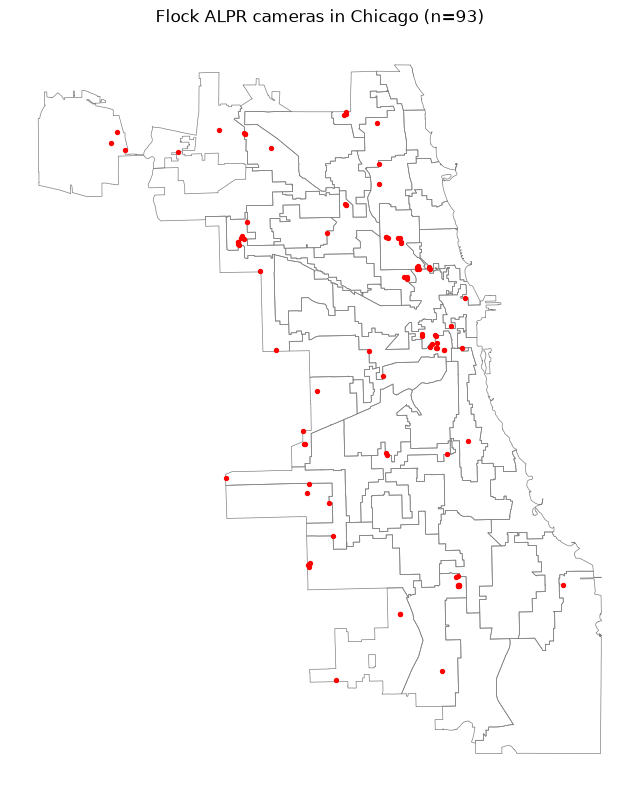

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

city = gpd.read_file(r"..\..\data\raw\chicago-city.geojson")
wards = gpd.read_file(r"..\..\data\raw\chicago-wards.geojson")

flock = cams.filter(pl.col("manufacturer").str.contains("(?i)flock"))
flock_gdf = gpd.GeoDataFrame(flock.to_dict(as_series=False), geometry=gpd.points_from_xy(flock["lon"], flock["lat"]), crs="EPSG:4326").clip(city)

ax = wards.plot(facecolor="none", edgecolor="gray", linewidth=0.5, figsize=(8, 10))
flock_gdf.plot(ax=ax, color="red", markersize=8)
ax.set_title(f"Flock ALPR cameras in Chicago (n={len(flock_gdf)})")
ax.set_axis_off()
plt.show()

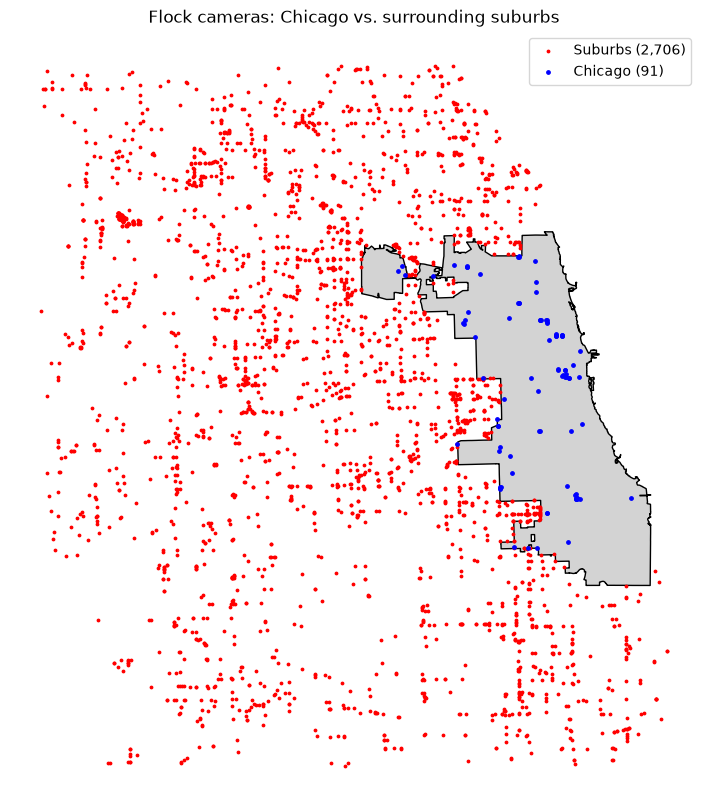

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

us_flock = gpd.read_file(r"..\..\data\raw\export.geojson")
city = gpd.read_file(r"..\..\data\raw\chicago-city.geojson")

metro = us_flock.cx[-88.4:-87.5, 41.45:42.2]           # box around the Chicago metro area (lon, lat)
inside = metro.clip(city)                               # cameras inside city limits
outside = metro[~metro.index.isin(inside.index)]        # everything else in the box

ax = city.plot(facecolor="lightgray", edgecolor="black", linewidth=1, figsize=(9, 10))
outside.plot(ax=ax, color="red", markersize=3, label=f"Suburbs ({len(outside):,})")
inside.plot(ax=ax, color="blue", markersize=6, label=f"Chicago ({len(inside):,})")
ax.set_title("Flock cameras: Chicago vs. surrounding suburbs")
ax.legend()
ax.set_axis_off()
plt.show()

In [ ]:
zcta = load_zcta()

print("Census ZCTA rows, columns:", zcta.shape) # (33772, 7) # Long Nice

Census ZCTA rows, columns: (33772, 7)


In [ ]:
print("number_of_unique_rows, number_of_columns)", zcta.unique().shape) # (33772, 7), no duplicates

number_of_unique_rows, number_of_columns) (33772, 7)


In [ ]:
zcta.schema

Schema([('zcta', String),
        ('median_household_income', Int64),
        ('population', Int64),
        ('land_sqmi', Float64),
        ('lat', Float64),
        ('lon', Float64),
        ('pop_per_sqmi', Float64)])

In [ ]:
zcta.glimpse()

Rows: 33772
Columns: 7
$ zcta                    <str> '00601', '00602', '00603', '00606', '00610', '00611', '00612', '00616', '00617', '00622'
$ median_household_income <i64> 19454, 21420, 20933, 20992, 24496, 20360, 24488, 21846, 25013, 26585
$ population              <i64> 16669, 37233, 48448, 5163, 25357, 1383, 62908, 9717, 22584, 7664
$ land_sqmi               <f64> 64.416, 30.327, 34.356, 44.334, 37.124, 10.649, 76.254, 10.879, 18.343, 31.168
$ lat                     <f64> 18.180555, 18.361945, 18.457399, 18.158327, 18.295304, 18.276316, 18.416727, 18.420408, 18.446889, 17.988103
$ lon                     <f64> -66.749961, -67.175597, -67.124867, -66.932928, -67.12518, -66.807165, -66.70009, -66.671986, -66.561154, -67.160357
$ pop_per_sqmi            <f64> 258.7711127670144, 1227.7178751607478, 1410.1758062638257, 116.4568953850318, 683.0352332722766, 129.871349422481, 824.9796731974716, 893.1887121978124, 1231.2053644442021, 245.89322381930185



In [ ]:
zcta.head()

zcta,median_household_income,population,land_sqmi,lat,lon,pop_per_sqmi
str,i64,i64,f64,f64,f64,f64
"""00601""",19454,16669,64.416,18.180555,-66.749961,258.771113
"""00602""",21420,37233,30.327,18.361945,-67.175597,1227.717875
"""00603""",20933,48448,34.356,18.457399,-67.124867,1410.175806
"""00606""",20992,5163,44.334,18.158327,-66.932928,116.456895
"""00610""",24496,25357,37.124,18.295304,-67.12518,683.035233


In [ ]:
zcta.null_count()

zcta,median_household_income,population,land_sqmi,lat,lon,pop_per_sqmi
u32,u32,u32,u32,u32,u32,u32
0,3225,0,0,0,0,0


In [ ]:
zcta.describe()

statistic,zcta,median_household_income,population,land_sqmi,lat,lon,pop_per_sqmi
str,str,f64,f64,f64,f64,f64,f64
"""count""","""33772""",30547.0,33772.0,33772.0,33772.0,33772.0,33772.0
"""null_count""","""0""",3225.0,0.0,0.0,0.0,0.0,0.0
"""mean""",null,78685.723999,10010.41869,83.612939,38.812406,-91.029273,1323.97879
"""std""",null,33365.493084,15099.693479,234.313861,5.358448,15.12551,5045.446932
"""min""","""00601""",2499.0,0.0,0.001,17.963613,-176.668606,0.0
"""25%""",null,57507.0,650.0,8.116,35.369444,-97.230236,18.890336
"""50%""",null,72067.0,2656.0,34.898,39.477204,-88.194451,79.134247
"""75%""",null,92000.0,13459.0,87.095,42.104067,-80.250311,705.087302
"""max""","""99929""",250001.0,140157.0,13680.117,71.264377,-65.307771,172782.608696


In [ ]:
# income capped by the Census at 250,001
zcta.filter(pl.col("median_household_income") == 250001).height # 118

118

In [ ]:
# ZCTAs where nobody lives
zcta.filter(pl.col("population") == 0).height # 598

598

In [ ]:
# most crowded ZCTAs (all in New York)
zcta.sort("pop_per_sqmi", descending=True).head(5)

zcta,median_household_income,population,land_sqmi,lat,lon,pop_per_sqmi
str,i64,i64,f64,f64,f64,f64
"""11109""",204885,7948,0.046,40.746616,-73.957009,172782.608696
"""10069""",233636,6509,0.041,40.777382,-73.98883,158756.097561
"""10028""",175121,49077,0.316,40.776447,-73.953383,155306.962025
"""10005""",190233,9439,0.073,40.706215,-74.008687,129301.369863
"""10128""",147772,57976,0.454,40.781498,-73.950199,127700.440529


In [ ]:
# Illinois only (ZIPs 600-629)
zcta_il = zcta.filter(pl.col("zcta").str.slice(0, 3).is_between(pl.lit("600"), pl.lit("629")))
print("Illinois ZCTAs:", zcta_il.shape) # (1396, 7)

Illinois ZCTAs: (1396, 7)


In [ ]:
zcta_il.null_count() # income missing for 57 Illinois ZCTAs

zcta,median_household_income,population,land_sqmi,lat,lon,pop_per_sqmi
u32,u32,u32,u32,u32,u32,u32
0,57,0,0,0,0,0


In [ ]:
zcta_il.describe()

statistic,zcta,median_household_income,population,land_sqmi,lat,lon,pop_per_sqmi
str,str,f64,f64,f64,f64,f64,f64
"""count""","""1396""",1339.0,1396.0,1396.0,1396.0,1396.0,1396.0
"""null_count""","""0""",57.0,0.0,0.0,0.0,0.0,0.0
"""mean""",null,80055.738611,9093.656877,39.74906,40.375806,-89.007592,1416.126671
"""std""",null,29034.680529,14921.241913,38.623208,1.420608,0.976481,4177.894913
"""min""","""60002""",13393.0,0.0,0.028,37.040124,-91.407737,0.0
"""25%""",null,61322.0,638.0,7.387,39.264927,-89.739298,20.345227
"""50%""",null,75417.0,1831.0,31.505,40.562795,-88.983829,61.036902
"""75%""",null,92917.0,10955.0,57.125,41.676605,-88.12381,798.268398
"""max""","""62999""",250001.0,108324.0,262.759,42.492576,-87.550204,47547.288777


What stands out (Census by ZIP / ZCTA):
- zcta.shape and zcta.unique().shape both give (33772, 7), so there are 33,772 ZCTAs (the Census version of ZIP codes) and no duplicate rows, but this is the whole country, not just Illinois.
- So, filtering to ZIPs that start with 600 to 629 gives zcta_il.shape = (1396, 7), which is the part we actually need since our cameras are only in Illinois.
- null_count() shows median_household_income is missing for 3,225 ZCTAs (57 of them in Illinois), usually places with very few households.
- However, 118 ZCTAs have an income of exactly 250,001, which honestly isn't a real median, it's the cap the Census uses for the highest incomes, so the richest ZIPs all look the same.
- Additionally, 598 ZCTAs have a population of 0, and sorting by pop_per_sqmi shows the most crowded ZCTAs are all in New York (e.g. 11109 with about 172,782 people per sq mile), so population density has a huge range and will probably need a log scale.

In [ ]:
ward_income = pl.read_csv("../data/raw/chicago-ward-income.csv")

print("Ward income rows, columns:", ward_income.shape) # (50, 10)

Ward income rows, columns: (50, 10)


In [ ]:
print("number_of_unique_rows, number_of_columns)", ward_income.unique().shape) # (50, 10)

number_of_unique_rows, number_of_columns) (50, 10)


In [ ]:
ward_income.schema # ward is Int64 here, but it's text in chicago-wards.geojson

Schema([('ward', Int64),
        ('acs_year', Int64),
        ('households_under_25k', Int64),
        ('households_25k_to_50k', Int64),
        ('households_50k_to_75k', Int64),
        ('households_75k_to_125k', Int64),
        ('households_125k_plus', Int64),
        ('households_total', Int64),
        ('pct_households_125k_plus', Float64),
        ('median_household_income_est', Int64)])

In [ ]:
#ward_income.glimpse()
ward_income.head()

ward,acs_year,households_under_25k,households_25k_to_50k,households_50k_to_75k,households_75k_to_125k,households_125k_plus,households_total,pct_households_125k_plus,median_household_income_est
i64,i64,i64,i64,i64,i64,i64,i64,f64,i64
1,2023,721,943,760,1721,6677,10822,61.7,148701
2,2023,482,627,613,1250,7494,10466,71.6,162714
3,2023,1820,1545,994,1772,4431,10562,42.0,101016
4,2023,1728,1288,950,1639,4573,10178,44.9,109259
5,2023,1584,1359,1134,1665,2861,8603,33.3,81742


In [ ]:
ward_income.null_count() # all 0

ward,acs_year,households_under_25k,households_25k_to_50k,households_50k_to_75k,households_75k_to_125k,households_125k_plus,households_total,pct_households_125k_plus,median_household_income_est
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0


In [ ]:
ward_income.describe()

statistic,ward,acs_year,households_under_25k,households_25k_to_50k,households_50k_to_75k,households_75k_to_125k,households_125k_plus,households_total,pct_households_125k_plus,median_household_income_est
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",25.5,2023.0,1522.4,1951.52,1550.32,2336.54,3956.36,11317.14,34.398,91102.66
"""std""",14.57738,0.0,769.413798,793.102439,583.415924,762.163387,2413.263492,1988.76009,19.587058,37505.28764
"""min""",1.0,2023.0,268.0,278.0,334.0,931.0,906.0,7629.0,10.0,43792.0
"""25%""",13.0,2023.0,980.0,1545.0,1134.0,1721.0,2172.0,9869.0,18.7,61861.0
"""50%""",26.0,2023.0,1459.0,2109.0,1593.0,2326.0,3281.0,11240.0,30.2,83978.0
"""75%""",38.0,2023.0,2097.0,2504.0,2019.0,2837.0,6045.0,12673.0,44.1,109259.0
"""max""",50.0,2023.0,3777.0,3328.0,2632.0,3971.0,10471.0,16181.0,78.9,170763.0


In [ ]:
# do the 5 brackets add up to households_total? (rows that DON'T match)
ward_income.filter(pl.sum_horizontal(pl.col("^households_.*k.*$")) != pl.col("households_total")).height # 0

0

In [ ]:
# poorest and richest wards
ward_income.sort("median_household_income_est").select("ward", "median_household_income_est", "pct_households_125k_plus").head(5)

ward,median_household_income_est,pct_households_125k_plus
i64,i64,f64
20,43792,10.0
24,46561,10.5
28,46909,15.7
16,47983,12.2
6,49174,15.6


In [ ]:
ward_income.sort("median_household_income_est", descending=True).select("ward", "median_household_income_est", "pct_households_125k_plus").head(5)

ward,median_household_income_est,pct_households_125k_plus
i64,i64,f64
42,170763,78.9
43,169756,77.9
44,168232,76.4
32,165944,74.4
2,162714,71.6


What stands out (Chicago ward income):
- ward_income.shape and ward_income.unique().shape both give (50, 10), so there's one row for each of the 50 wards and no duplicates, and null_count() is 0 for every column.
- The 5 income brackets add up exactly to households_total for every ward (0 rows don't match), so the counts are consistent with each other.
- However, ward_income.schema shows ward is Int64 here, while in chicago-wards.geojson ward is text ("1" to "50"), so we'll have to cast one of them before joining or nothing will match.
- Sorting by median_household_income_est shows ward 20 is the lowest at $43,792 with only 10% of households over $125k, while ward 42 is the highest at $170,763 with 78.9% over $125k, so honestly the gap between wards is huge.
- Additionally, median_household_income_est is an estimate (it says "_est" in the name), since the Census doesn't publish data by ward, so it's built from smaller Census areas and isn't an official number.

In [ ]:
import geopandas as gpd
wards = gpd.read_file("../data/raw/chicago-wards.geojson")
print("Wards rows, columns:", wards.shape) # (50, 2): ward + geometry

Wards rows, columns: (50, 2)


In [ ]:
wards.dtypes # ward is text (str)

ward             str
geometry    geometry
dtype: object

In [ ]:
wards.head()

,ward,geometry
0,1,"MULTIPOLYGON (((-87.68777 41.92858, -87.68776 ..."
1,2,"MULTIPOLYGON (((-87.62517 41.904, -87.625 41.9..."
2,3,"MULTIPOLYGON (((-87.61992 41.86577, -87.61985 ..."
3,4,"MULTIPOLYGON (((-87.62429 41.877, -87.62429 41..."
4,5,"MULTIPOLYGON (((-87.5603 41.76636, -87.56058 4..."


In [ ]:
wards.isna().sum() # 0 missing

ward        0
geometry    0
dtype: int64

In [ ]:
wards["ward"].nunique() # 50

50

In [ ]:
wards.crs # EPSG:4326, so plain lat/lon

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [ ]:
# broken shapes
wards.loc[~wards.geometry.is_valid, "ward"] # 6 wards: 11, 12, 27, 28, 40, 50

10    11
11    12
26    27
27    28
39    40
49    50
Name: ward, dtype: str

In [ ]:
# ward size in square miles (convert to an Illinois map projection first, since lat/lon degrees aren't miles)
(wards.to_crs(26971).area / 2_589_988).describe() # 1.1 to 20.7 sq mi, median 4.0

count    50.000000
mean      4.628317
std       3.432575
min       1.122188
25%       2.744677
50%       4.018880
75%       5.179211
max      20.709242
dtype: float64

What stands out (Chicago wards):
- wards.shape gives (50, 2), so there's one row per ward with just a ward number and a geometry (the shape of the ward), and wards.isna().sum() shows nothing is missing.
- wards["ward"].nunique() gives 50, so every ward from 1 to 50 shows up exactly once, and wards.crs is EPSG:4326, which means the coordinates are plain lat/lon like our camera data.
- However, geometry.is_valid shows 6 ward shapes are invalid (wards 11, 12, 27, 28, 40, and 50), so placing cameras inside wards could give wrong answers for those unless we fix them with make_valid() first.
- Additionally, since lat/lon are in degrees and not miles, I had to convert to an Illinois map projection (to_crs(26971)) before calculating area, otherwise the areas would be meaningless.
- So, the wards go from about 1.1 to 20.7 square miles with a median of 4.0, which matters because a big ward will naturally have more cameras, so we should compare cameras per square mile, not raw counts.

In [ ]:
city = gpd.read_file("../data/raw/chicago-city.geojson")
print(city.shape, city.explode().shape) # (1, 1) -> (2, 1): 1 feature but 2 separate pieces

(1, 1) (2, 1)


In [ ]:
# city area vs. all wards added up
(city.to_crs(26971).area / 2_589_988).sum(), (wards.to_crs(26971).area / 2_589_988).sum() # 231.37 vs 231.42 sq mi

(np.float64(231.37285210817072), np.float64(231.4158280773379))

What stands out (Chicago city boundary):
- city.shape gives (1, 1), so the whole file is just one row with one geometry and no other columns, so the only thing it can be used for is the shape of the city.
- However, city.explode().shape gives (2, 1), so the one feature is actually 2 separate pieces, which is probably the main city plus the O'Hare area that's connected by a thin strip.
- The city works out to about 231.37 square miles after converting to the Illinois projection, and all the wards added up give 231.42, so the two files basically agree on what "Chicago" is.
- So, this boundary is better than the lat/lon box I used before (cell 13), since the box also grabbed some inner suburbs that aren't actually part of Chicago.
- Additionally, since the wards cover the same area, we could get the city outline by merging the wards, but keeping this file is simpler for clipping cameras to the city on the maps.

---

## Step 2: Anomalies

| Dataset | Anomaly | Rows affected | What I did |
|---|---|---|---|
| OSM | Axis spelled two ways ("Axis communications" with a lowercase c) | 500 | Fixed, merged into one name |
| OSM | `manufacturer` missing | 643 (355 in Chicago) | Flagged, labeled as "Unknown" |
| OSM | `operator` missing | 7,064 | Left it, not used in my plots |
| OSM | `timestamp` is the last edit, not when the camera was added | all edited cameras | Only used never-edited cameras (`version == 1`, 1,047 in Chicago) in R4 |
| OSM | Big mapping spike in 2026 Q3, mostly Axis cameras in ward 41 (O'Hare) | 529 Axis, 311 in ward 41 | Flagged in the R4 note |
| Atlas | Exact duplicate rows (Burleson PD, Orlando PD) | 2 | Flagged |
| Atlas | Missing values written as "" instead of blank | 7,203 in Vendor | Fixed by the loader (turned into nulls) |
| Atlas | "FRT" is the same as "Face Recognition" | 6 | Fixed by the loader |
| Atlas | Dates that couldn't be read | 4,863 missing after loading vs. 1,898 empty in the raw file | Turned into nulls by the loader |
| Atlas | `vendor` sometimes lists more than one company | 19 different strings with "Flock" | Left it |
| Wards | Invalid ward shapes | 6 (wards 11, 12, 27, 28, 40, 50) | Fixed with `make_valid()` |
| Wards / income | `ward` is text in one file and a number in the other | 50 | Fixed, changed to text before joining |

---

## Setup for the plots
This cell puts each camera into the Chicago ward it's inside, and counts the cameras in each ward. All the plots below use it.

In [ ]:

import geopandas as gpd
import matplotlib.pyplot as plt

wards = gpd.read_file("../data/raw/chicago-wards.geojson")
wards["geometry"] = wards.geometry.make_valid() # fix the 6 invalid ward shapes
wards["area_sqmi"] = wards.to_crs(26971).area / 2_589_988 # Illinois projection -> sq miles

# clean manufacturer: merge the two Axis spellings, label missing ones, flag Flock
cams_clean = cams.with_columns(
    pl.col("manufacturer")
    .str.replace("Axis communications", "Axis Communications")
    .fill_null("Unknown")
    .alias("manufacturer"),
    pl.col("manufacturer").str.contains("(?i)flock").fill_null(False).alias("is_flock"),
)

# polars -> GeoDataFrame, then keep only cameras inside a ward (= inside Chicago)
cams_gdf = gpd.GeoDataFrame(
    cams_clean.select("osm_id", "manufacturer", "is_flock", "version", "timestamp").to_dict(as_series=False),
    geometry=gpd.points_from_xy(cams_clean["lon"], cams_clean["lat"]),
    crs="EPSG:4326",
)
chi = gpd.sjoin(cams_gdf, wards[["ward", "geometry"]], predicate="within").drop(columns="index_right")
print("cameras in Chicago:", len(chi), "| Flock:", chi["is_flock"].sum()) # 1327 | 93

# one row per ward: camera counts + area + income
per_ward = wards[["ward", "area_sqmi"]].copy()
per_ward["cameras"] = per_ward["ward"].map(chi.groupby("ward").size()).fillna(0).astype(int)
per_ward["flock"] = per_ward["ward"].map(chi[chi["is_flock"]].groupby("ward").size()).fillna(0).astype(int)
per_ward["cams_per_sqmi"] = per_ward["cameras"] / per_ward["area_sqmi"]
income = ward_income.with_columns(pl.col("ward").cast(pl.String)).to_dict(as_series=False) # ward: Int64 -> text to match the geojson
per_ward = per_ward.merge(gpd.pd.DataFrame(income), on="ward")
print(per_ward.shape) # (50, 14)

cameras in Chicago: 1327 | Flock: 93
(50, 14)


## Step 3: Distributions
D1 and D2 look at one feature at a time.

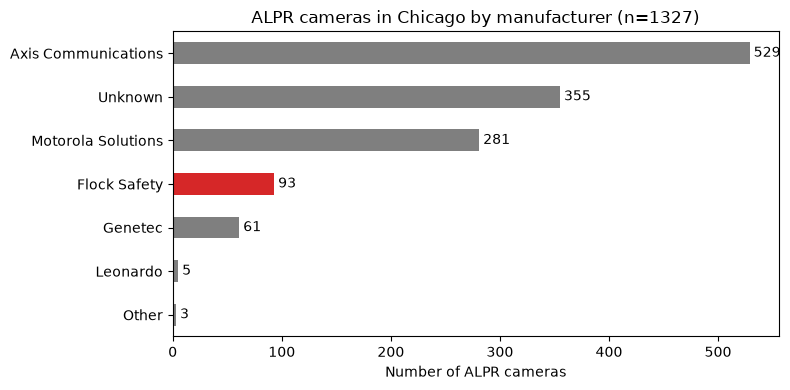

In [ ]:
counts = chi["manufacturer"].value_counts()
top = counts.head(6)
top["Other"] = counts.iloc[6:].sum() # lump the long tail together
top = top.sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
top.plot.barh(ax=ax, color=["tab:red" if "Flock" in m else "tab:gray" for m in top.index])
for i, v in enumerate(top):
    ax.text(v, i, f" {v}", va="center") # count at the end of each bar
ax.set_xlabel("Number of ALPR cameras")
ax.set_ylabel("")
ax.set_title(f"ALPR cameras in Chicago by manufacturer (n={len(chi)})")
plt.tight_layout()
plt.show()

So what? (D1: ALPR cameras in Chicago by manufacturer)
- Axis Communications has the most cameras in Chicago (529), and Flock Safety only has 93.
- Honestly I expected Flock to be the biggest bar, since it's the biggest in Illinois overall.
- The Unknown bar is the 2nd biggest (355), so a lot of cameras don't have a manufacturer listed.
- So, in Chicago most of the ALPR cameras are not Flock.

What next? (D1: ALPR cameras in Chicago by manufacturer)
- Question: Why are there so few Flock cameras in Chicago compared to the rest of Illinois?
- Comparison: Make the same bar chart for the suburbs around Chicago and see if Flock is bigger there.
- Subgroup: Look at only the Unknown cameras to see if we can figure out who made them from all_tags.

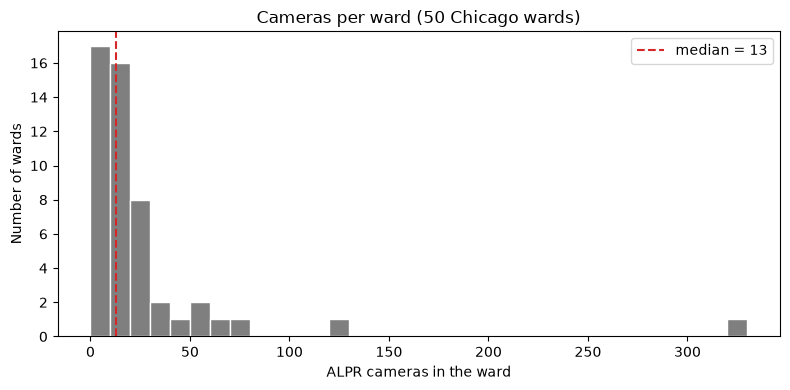

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(per_ward["cameras"], bins=range(0, per_ward["cameras"].max() + 10, 10), color="tab:gray", edgecolor="white")
ax.axvline(per_ward["cameras"].median(), color="tab:red", linestyle="--", label=f"median = {per_ward['cameras'].median():.0f}")
ax.set_xlabel("ALPR cameras in the ward")
ax.set_ylabel("Number of wards")
ax.set_title("Cameras per ward (50 Chicago wards)")
ax.legend()
plt.tight_layout()
plt.show()

So what? (D2: Cameras per ward)
- Most wards have a small number of cameras, the median is 13.
- There's one ward way out on the right with over 300 cameras, which is a big outlier.
- The histogram is skewed to the right, since most of the bars are on the left side.
- So, a few wards have a lot of cameras, while most wards only have a few.

What next? (D2: Cameras per ward)
- Question: What makes some wards have way more cameras than others?
- Subgroup: Take out ward 41 (O'Hare) and see what the histogram looks like without the outlier.
- Comparison: Use cameras per square mile instead of total cameras, since some wards are bigger than others.

## Step 4 and 5: Relationships, So What? and What Next?
R1, R2, R4, and the 4.1 map relate two or more features. The notes under each plot answer "so what?" and "what next?".

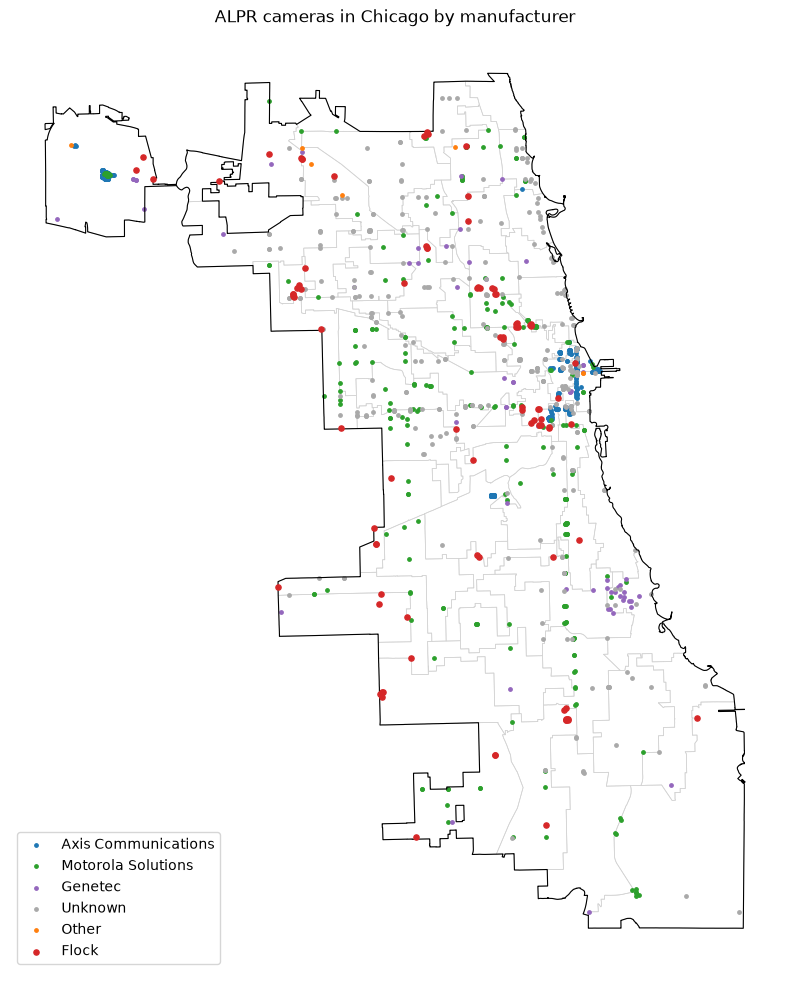

In [ ]:
city = gpd.read_file("../data/raw/chicago-city.geojson")
main = ["Axis Communications", "Motorola Solutions", "Genetec", "Unknown"]

fig, ax = plt.subplots(figsize=(8, 10))
wards.plot(ax=ax, facecolor="none", edgecolor="lightgray", linewidth=0.5)
city.boundary.plot(ax=ax, color="black", linewidth=0.8)
for name, color in zip(main, ["tab:blue", "tab:green", "tab:purple", "darkgray"]):
    chi[chi["manufacturer"] == name].plot(ax=ax, color=color, markersize=6, label=name)
chi[~chi["manufacturer"].isin(main) & ~chi["is_flock"]].plot(ax=ax, color="tab:orange", markersize=6, label="Other")
chi[chi["is_flock"]].plot(ax=ax, color="tab:red", markersize=14, label="Flock", zorder=5) # Flock drawn on top
ax.set_title("ALPR cameras in Chicago by manufacturer")
ax.legend(loc="lower left")
ax.set_axis_off()
plt.tight_layout()
plt.show()

So what? (R1: Map of ALPR cameras in Chicago by manufacturer)
- The blue Axis cameras are mostly bunched up downtown by the lake and at O'Hare (the shape in the top left).
- The green Motorola cameras are spread out more, mostly on the South and West Sides.
- The red Flock cameras are scattered around the neighborhoods, not downtown.
- Additionally, some areas of the map have almost no cameras, but that could just mean nobody mapped them yet.

What next? (R1: Map of ALPR cameras in Chicago by manufacturer)
- Question: Who runs each group of cameras, the police, the state, or someone else?
- Subgroup: Color the map by operator instead of manufacturer (e.g. Chicago Police Department vs. Illinois State Police).
- Another dataset: Add a map of major roads or expressways to see if the Motorola cameras line up with them.

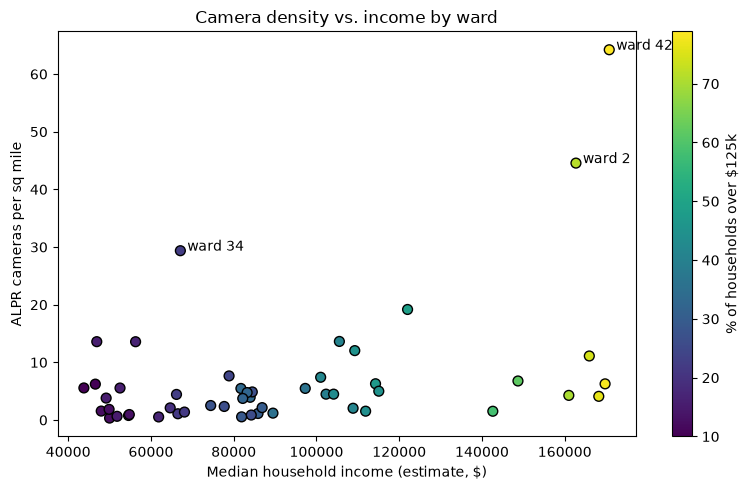

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(per_ward["median_household_income_est"], per_ward["cams_per_sqmi"],
                c=per_ward["pct_households_125k_plus"], cmap="viridis", s=50, edgecolor="black")
for _, row in per_ward.nlargest(3, "cams_per_sqmi").iterrows(): # label the 3 densest wards
    ax.annotate(f"ward {row['ward']}", (row["median_household_income_est"], row["cams_per_sqmi"]),
                xytext=(5, 0), textcoords="offset points")
ax.set_xlabel("Median household income (estimate, $)")
ax.set_ylabel("ALPR cameras per sq mile")
ax.set_title("Camera density vs. income by ward")
fig.colorbar(sc, label="% of households over $125k")
plt.tight_layout()
plt.show()

So what? (R2: Camera density vs. income by ward)
- Most wards have less than 15 cameras per square mile, no matter their income.
- The two wards with the most cameras per square mile (ward 42 and ward 2) are also two of the richest wards.
- However, ward 34 has a lot of cameras per square mile even though its income is in the middle.
- So, richer wards might have slightly more cameras, but it's a weak relationship and doesn't prove income causes it.

What next? (R2: Camera density vs. income by ward)
- Question: Is the relationship between income and cameras real, or is it just because downtown wards are busier?
- Subgroup: Take out the downtown wards (like 42 and 2) and see if the relationship is still there.
- Another dataset: Join crime data by ward to see if wards with more crime have more cameras.

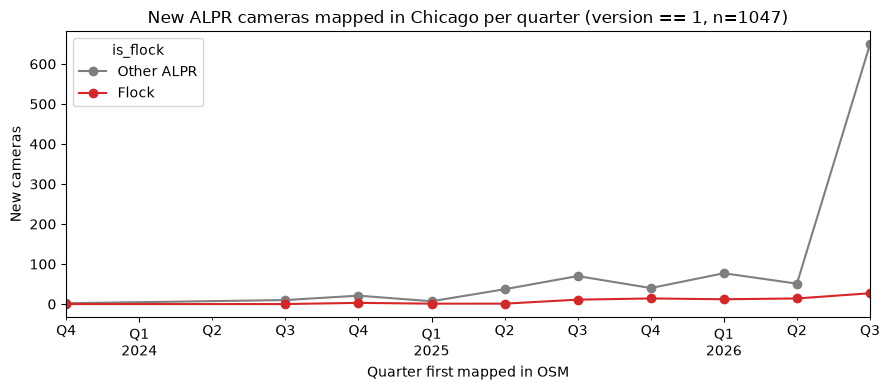

In [ ]:
new = chi[chi["version"] == 1].copy() # never edited, so timestamp = when it was first mapped
new["quarter"] = new["timestamp"].dt.tz_localize(None).dt.to_period("Q")
by_q = (new.groupby(["quarter", "is_flock"]).size().unstack(fill_value=0)
           .rename(columns={True: "Flock", False: "Other ALPR"}))

fig, ax = plt.subplots(figsize=(9, 4))
by_q.plot(ax=ax, marker="o", color={"Flock": "tab:red", "Other ALPR": "tab:gray"})
ax.set_xlabel("Quarter first mapped in OSM")
ax.set_ylabel("New cameras")
ax.set_title(f"New ALPR cameras mapped in Chicago per quarter (version == 1, n={len(new)})")
plt.tight_layout()
plt.show()

So what? (R4: New ALPR cameras mapped in Chicago per quarter)
- The number of new cameras mapped goes up slowly over time.
- There's a huge jump in 2026 Q3, where hundreds of non-Flock cameras were mapped in one quarter.
- Flock (red) stays low the whole time, but slowly goes up to 27 in 2026 Q3.
- So, this shows when cameras were added to OSM, not when they were actually installed, so the jump might just be someone mapping a lot of cameras at once.

What next? (R4: New ALPR cameras mapped in Chicago per quarter)
- Question: Is Flock actually growing in Chicago, or are people just mapping more cameras?
- Subgroup: Take out the big 2026 Q3 jump (the Axis cameras at O'Hare) to see the trend without it.
- Comparison: Make the same plot for all of Illinois to see if Flock is growing faster outside of Chicago.

In [ ]:
# what's behind the 2026 Q3 spike
spike = new[new["quarter"] == new["quarter"].max()]

spike["manufacturer"].value_counts().head(5), spike["ward"].value_counts().head(5), spike["timestamp"].dt.date.value_counts().head(5)

(manufacturer
 Axis Communications    529
 Motorola Solutions      61
 Genetec                 33
 Flock Safety            27
 Unknown                 22
 Name: count, dtype: int64,
 ward
 41    311
 42     82
 12     62
 4      38
 28     36
 Name: count, dtype: int64,
 timestamp
 2026-09-18    310
 2026-09-19    154
 2026-09-20     84
 2026-07-07     11
 2026-09-21     11
 Name: count, dtype: int64)

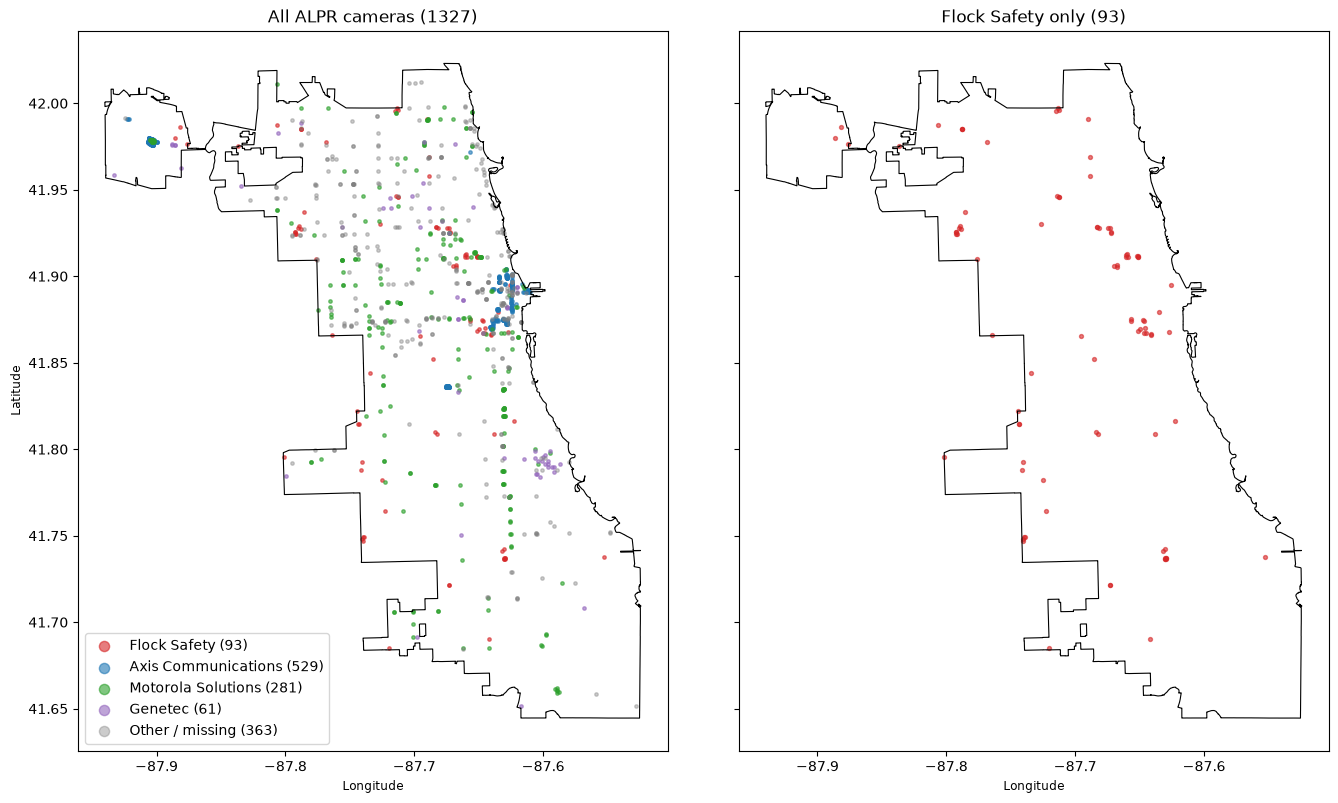

In [ ]:
import numpy as np

# 4.1 Map of Chicago: all ALPR cameras by manufacturer (left), Flock only (right)
# uses `chi` from the setup cell (cameras inside the real city boundary)
city = gpd.read_file("../data/raw/chicago-city.geojson")
colors = {"Flock Safety": "tab:red", "Axis Communications": "tab:blue", "Motorola Solutions": "tab:green", "Genetec": "tab:purple"}

fig, ax = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
for a in ax:
    city.boundary.plot(ax=a, color="black", linewidth=0.8) # city outline on both maps

for name, color in colors.items():
    sub = chi[chi["manufacturer"] == name]
    sub.plot(ax=ax[0], markersize=6, alpha=0.6, color=color, label=f"{name} ({len(sub)})")
other = chi[~chi["manufacturer"].isin(colors)] # includes "Unknown" (missin
other.plot(ax=ax[0], markersize=6, alpha=0.4, color="gray", label=f"Other / missing ({len(other)})")
ax[0].legend(loc="lower left", markerscale=3)
ax[0].set_title(f"All ALPR cameras ({len(chi)})")

flock = chi[chi["is_flock"]]
flock.plot(ax=ax[1], markersize=8, alpha=0.6, color="tab:red")
ax[1].set_title(f"Flock Safety only ({len(flock)})")

for a in ax:
    a.set_aspect(1 / np.cos(np.radians(41.84))) # so the map isn't stretched
    a.set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")
ax[1].set_ylabel("")
plt.tight_layout()
plt.show()

## Step 6: Revised Research Questions

1. **(revised)** How many new ALPR cameras are being mapped in Chicago each quarter, and is Flock growing faster than the other manufacturers?
   - **What changed and why:** I narrowed it to Chicago and split Flock vs. other cameras, since R4 showed a big jump that came from other cameras.
2. **(revised)** Do richer Chicago wards have more ALPR cameras per square mile than poorer wards?
   - **What changed and why:** I switched from ZIP codes to Chicago wards, since the ward data fits Chicago better.
3. **(unchanged)** Do ALPR-using agencies also use other surveillance technologies (like face recognition and drones) more than non-ALPR agencies?
   - **Why:** I explored the Atlas data but haven't plotted it yet.
4. **(revised)** Which Chicago wards have the most ALPR cameras per square mile, and which manufacturers are in them?
   - **What changed and why:** I compared wards inside Chicago instead of different cities, and looked at all ALPR cameras instead of only Flock, since most of Chicago's cameras are not Flock.